In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
figsize=(20, 8)

In [2]:
df2 = pd.concat([
    pd.read_csv('results_20261025_225531/all_results.csv'),
    pd.read_csv('results_20261025_183402/all_results.csv'),
    pd.read_csv('results_20261025_162053/all_results.csv')
], ignore_index=True)

df2 = df2[df2['feature'] == 'Continent']
print(f'Embedding methods : {df2['embedding'].unique()}')

Embedding methods : ['pca' 'lle' 'wavelet' 'fft' 'autoencoder' 'umap' 'nnclr_cnn' 'nnclr_lstm'
 'TiViT-CLIP-B16' 'TiViT-CLIP-H14' 'TiViT+MantisV2' 'TS2Vec'
 'Chronos-T5-small' 'Chronos-Bolt-base' 'Mantis-8M' 'MantisPlus'
 'Mantis-Utica' 'MantisV2']


In [3]:
df = pd.read_csv('results_20261027_101142/all_results.csv')
df = pd.concat([df , df2[df2['embedding'].isin(['pca' ,'lle' ,'wavelet' ,'fft' ,'autoencoder' ,'umap' ,'nnclr_cnn', 'nnclr_lstm',
 'TiViT-CLIP-B16', 'TiViT-CLIP-H14', 'TS2Vec',
 'Chronos-T5-small' ,'Chronos-Bolt-base'])]])
print(f'Embedding methods : {df['embedding'].unique()}')

Embedding methods : ['No-embed' 'pca' 'lle' 'wavelet' 'fft' 'autoencoder' 'umap' 'nnclr_cnn'
 'nnclr_lstm' 'TiViT-CLIP-B16' 'TiViT-CLIP-H14' 'TiViT+MantisV2' 'TS2Vec'
 'Chronos-T5-small' 'Chronos-Bolt-base' 'Mantis-8M' 'MantisPlus'
 'Mantis-Utica' 'MantisV2' 'Mantis-8M_pretrain_continued'
 'MantisPlus_pretrain_continued' 'Mantis-Utica_pretrain_continued'
 'MantisV2_pretrain_continued' 'Mantis-8M_pretrain_scratch'
 'MantisV2_pretrain_scratch' 'graph' 'tda']


In [4]:
categories = {
    'Baseline': ['No-embed'],
    'Dimensionality reduction': ['pca', 'lle', 'umap'],
    'Signal / topological / graph': ['wavelet', 'fft', 'tda', 'graph'],
    'Learned (self-supervised)': ['autoencoder', 'nnclr_cnn', 'nnclr_lstm', 'TS2Vec'],
    'Foundation models': [
        'TiViT-CLIP-B16', 'TiViT-CLIP-H14', 'TiViT+MantisV2',
        'Chronos-T5-small', 'Chronos-Bolt-base',
        'Mantis-8M', 'MantisPlus', 'Mantis-Utica', 'MantisV2',
    ],
    'Mantis: continued pretraining': [
        'Mantis-8M_pretrain_continued', 'MantisPlus_pretrain_continued',
        'Mantis-Utica_pretrain_continued', 'MantisV2_pretrain_continued',
    ],
    'Mantis: pretrained from scratch': [
        'Mantis-8M_pretrain_scratch', 'MantisV2_pretrain_scratch',
    ],
}

# 2. One color per category
cat_colors = dict(zip(categories, sns.color_palette("tab10", len(categories))))

# 3. embedding -> color, and the x order (grouped by category)
emb_colors = {emb: cat_colors[cat] for cat, embs in categories.items() for emb in embs}
order = [emb for embs in categories.values() for emb in embs]
order = [e for e in order if e in df['embedding'].unique()]  # drop any missing ones

In [30]:
df_event = df[df['feature'] == 'event_type']
df_continent = df[df['feature'] == 'Continent']
print('Best accuracy when classified per event type:')
for i,row in df_event[df_event['accuracy'] == df_event['accuracy'].max()].iterrows():
    print(f'window = {row['window']} days, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
    
print('\n Worst accuracy when classified per event type:')
for i,row in df_event[df_event['accuracy'] == df_event['accuracy'].min()].iterrows():
    print(f'window = {row['window']} days, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
    

print('\nBest accuracy when classified per continent:')
for i,row in df_continent[df_continent['accuracy'] == df_continent['accuracy'].max()].iterrows():
    print(f'window = {row['window']} days, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
    
print('\nWorst accuracy when classified per continent:')
for i,row in df_continent[df_continent['accuracy'] == df_continent['accuracy'].min()].iterrows():
    print(f'window = {row['window']} days, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
    

Best accuracy when classified per event type:
window = 30 days, embedding method = Chronos-T5-small, classifier = logreg, accuracy = 0.854
window = 30 days, embedding method = Mantis-8M, classifier = svm, accuracy = 0.854

 Worst accuracy when classified per event type:
window = 7 days, embedding method = nnclr_lstm, classifier = nb, accuracy = 0.414

Best accuracy when classified per continent:
window = 30 days, embedding method = TiViT-CLIP-H14, classifier = knn, accuracy = 0.542

Worst accuracy when classified per continent:
window = 7 days, embedding method = nnclr_lstm, classifier = nb, accuracy = 0.135


In [31]:
for window in [7,14,30]:
    df_window = df[df['window'] == window]
    
    
    print(f'\nBest accuracy when classified using a {window} days window:')
    for i,row in df_window[df_window['accuracy'] == df_window['accuracy'].max()].iterrows():
        print(f'feature = {row['feature']}, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
        
    print(f'\nWorst accuracy when classified using a {window} days window')
    for i,row in df_window[df_window['accuracy'] == df_window['accuracy'].min()].iterrows():
        print(f'feature = {row['feature']}, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
        
    


Best accuracy when classified using a 7 days window:
feature = event_type, embedding method = MantisPlus, classifier = logreg, accuracy = 0.778

Worst accuracy when classified using a 7 days window
feature = Continent, embedding method = nnclr_lstm, classifier = nb, accuracy = 0.135

Best accuracy when classified using a 14 days window:
feature = event_type, embedding method = Chronos-T5-small, classifier = logreg, accuracy = 0.843

Worst accuracy when classified using a 14 days window
feature = Continent, embedding method = nnclr_cnn, classifier = nb, accuracy = 0.199

Best accuracy when classified using a 30 days window:
feature = event_type, embedding method = Chronos-T5-small, classifier = logreg, accuracy = 0.854
feature = event_type, embedding method = Mantis-8M, classifier = svm, accuracy = 0.854

Worst accuracy when classified using a 30 days window
feature = Continent, embedding method = nnclr_cnn, classifier = nb, accuracy = 0.199


In [5]:
for window in [7,14,30]:
    df_window = df[(df['window'] == window) & (df['feature'] == 'event_type')]
    
    
    print(f'\nBest accuracy when classified using a {window} days window:')
    for i,row in df_window[df_window['accuracy'] == df_window['accuracy'].max()].iterrows():
        print(f'feature = {row['feature']}, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
        
    print(f'\nWorst accuracy when classified using a {window} days window')
    for i,row in df_window[df_window['accuracy'] == df_window['accuracy'].min()].iterrows():
        print(f'feature = {row['feature']}, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
        
    


Best accuracy when classified using a 7 days window:
feature = event_type, embedding method = MantisPlus, classifier = logreg, accuracy = 0.778

Worst accuracy when classified using a 7 days window
feature = event_type, embedding method = nnclr_lstm, classifier = nb, accuracy = 0.414

Best accuracy when classified using a 14 days window:
feature = event_type, embedding method = Chronos-T5-small, classifier = logreg, accuracy = 0.843

Worst accuracy when classified using a 14 days window
feature = event_type, embedding method = Mantis-8M_pretrain_continued, classifier = dt, accuracy = 0.471

Best accuracy when classified using a 30 days window:
feature = event_type, embedding method = Chronos-T5-small, classifier = logreg, accuracy = 0.854
feature = event_type, embedding method = Mantis-8M, classifier = svm, accuracy = 0.854

Worst accuracy when classified using a 30 days window
feature = event_type, embedding method = MantisPlus_pretrain_continued, classifier = dt, accuracy = 0.46


In [32]:
for window in [7,14,30]:
    df_window = df[(df['window'] == window) & (df['feature'] == 'Continent')]
    
    
    print(f'\nBest accuracy when classified using a {window} days window:')
    for i,row in df_window[df_window['accuracy'] == df_window['accuracy'].max()].iterrows():
        print(f'feature = {row['feature']}, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
        
    print(f'\nWorst accuracy when classified using a {window} days window')
    for i,row in df_window[df_window['accuracy'] == df_window['accuracy'].min()].iterrows():
        print(f'feature = {row['feature']}, embedding method = {row['embedding']}, classifier = {row['classifier']}, accuracy = {np.round(row['accuracy'],3)}')
        
    


Best accuracy when classified using a 7 days window:
feature = Continent, embedding method = TiViT-CLIP-H14, classifier = logreg, accuracy = 0.49

Worst accuracy when classified using a 7 days window
feature = Continent, embedding method = nnclr_lstm, classifier = nb, accuracy = 0.135

Best accuracy when classified using a 14 days window:
feature = Continent, embedding method = Mantis-8M, classifier = xgboost, accuracy = 0.514

Worst accuracy when classified using a 14 days window
feature = Continent, embedding method = nnclr_cnn, classifier = nb, accuracy = 0.199

Best accuracy when classified using a 30 days window:
feature = Continent, embedding method = TiViT-CLIP-H14, classifier = knn, accuracy = 0.542

Worst accuracy when classified using a 30 days window
feature = Continent, embedding method = nnclr_cnn, classifier = nb, accuracy = 0.199


Text(0.5, 0.98, 'Barplot of accuracy score per embedding method')

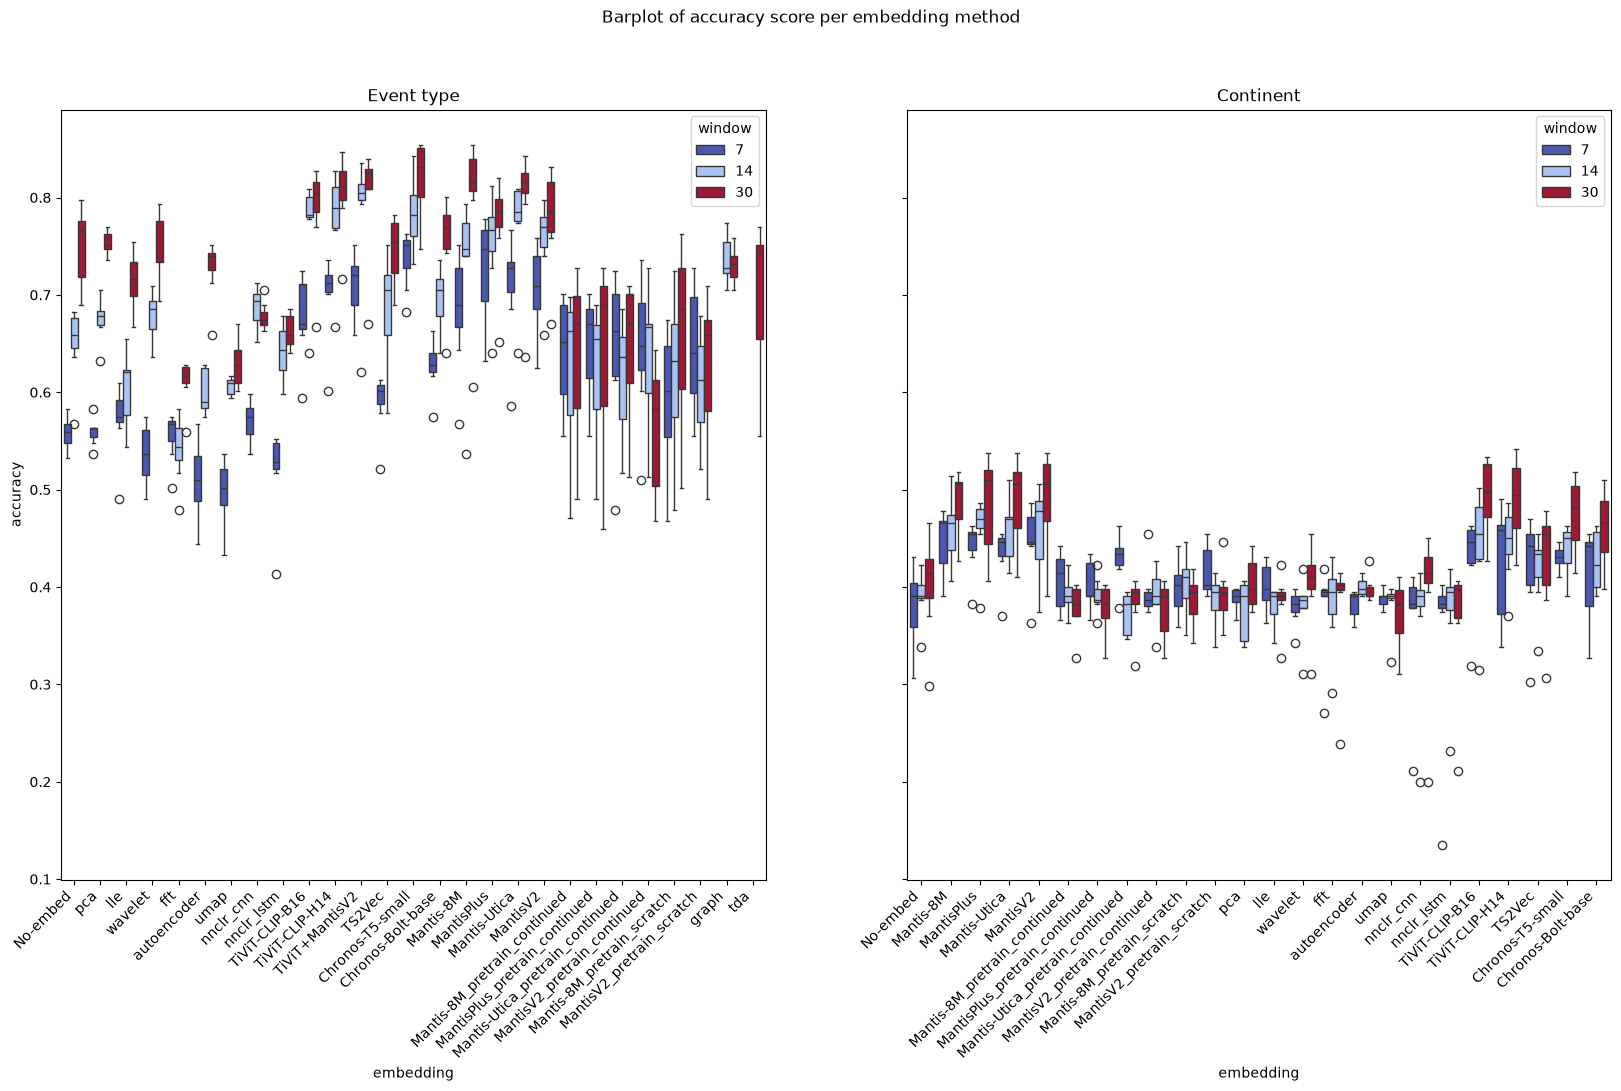

In [7]:
fig, axes = plt.subplots(
        nrows=1, 
        ncols=2, 
        figsize=(20, 10), sharey= True

    )

sns.boxplot(
    data=df[df['feature'] == 'event_type'],
    x='embedding',
    y='accuracy',
    hue='window',
    palette='coolwarm',
    ax=axes[0]
)
axes[0].set_title('Event type')
sns.boxplot(
    data=df[df['feature'] == 'Continent'].drop(columns='error').dropna(),
    x='embedding',
    y='accuracy',
    hue='window',
    palette='coolwarm',
    ax=axes[1]
)
#axes[1].set_title('Barplot of accuracy score per embedding method for continent classification')
axes[1].set_title('Continent')
axes[0].tick_params("x", rotation=45, rotation_mode="xtick")
axes[1].tick_params("x", rotation=45, rotation_mode="xtick")
fig.suptitle('Barplot of accuracy score per embedding method')

Text(0.5, 1.0, 'Barplot of accuracy score per embedding method for event type classification')

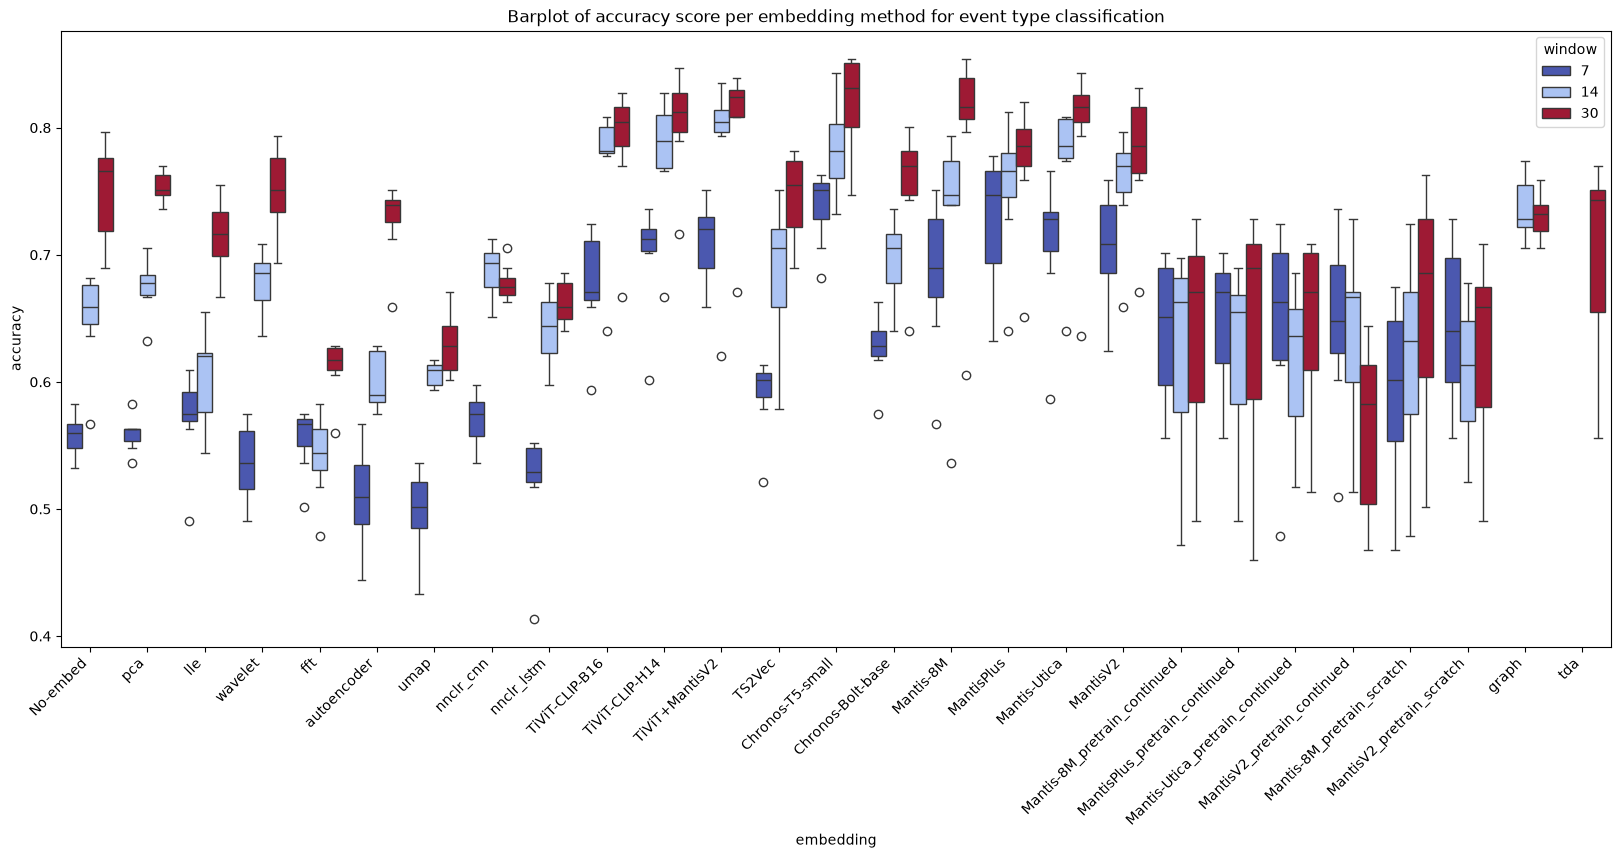

In [26]:
# 
plt.figure(figsize=(20, 8))
sns.boxplot(
    data=df[df['feature'] == 'event_type'],
    x='embedding',
    y='accuracy',
    hue='window',
    palette='coolwarm'
)
plt.tick_params("x", rotation=45, rotation_mode="xtick")
plt.title('Barplot of accuracy score per embedding method for event type classification')

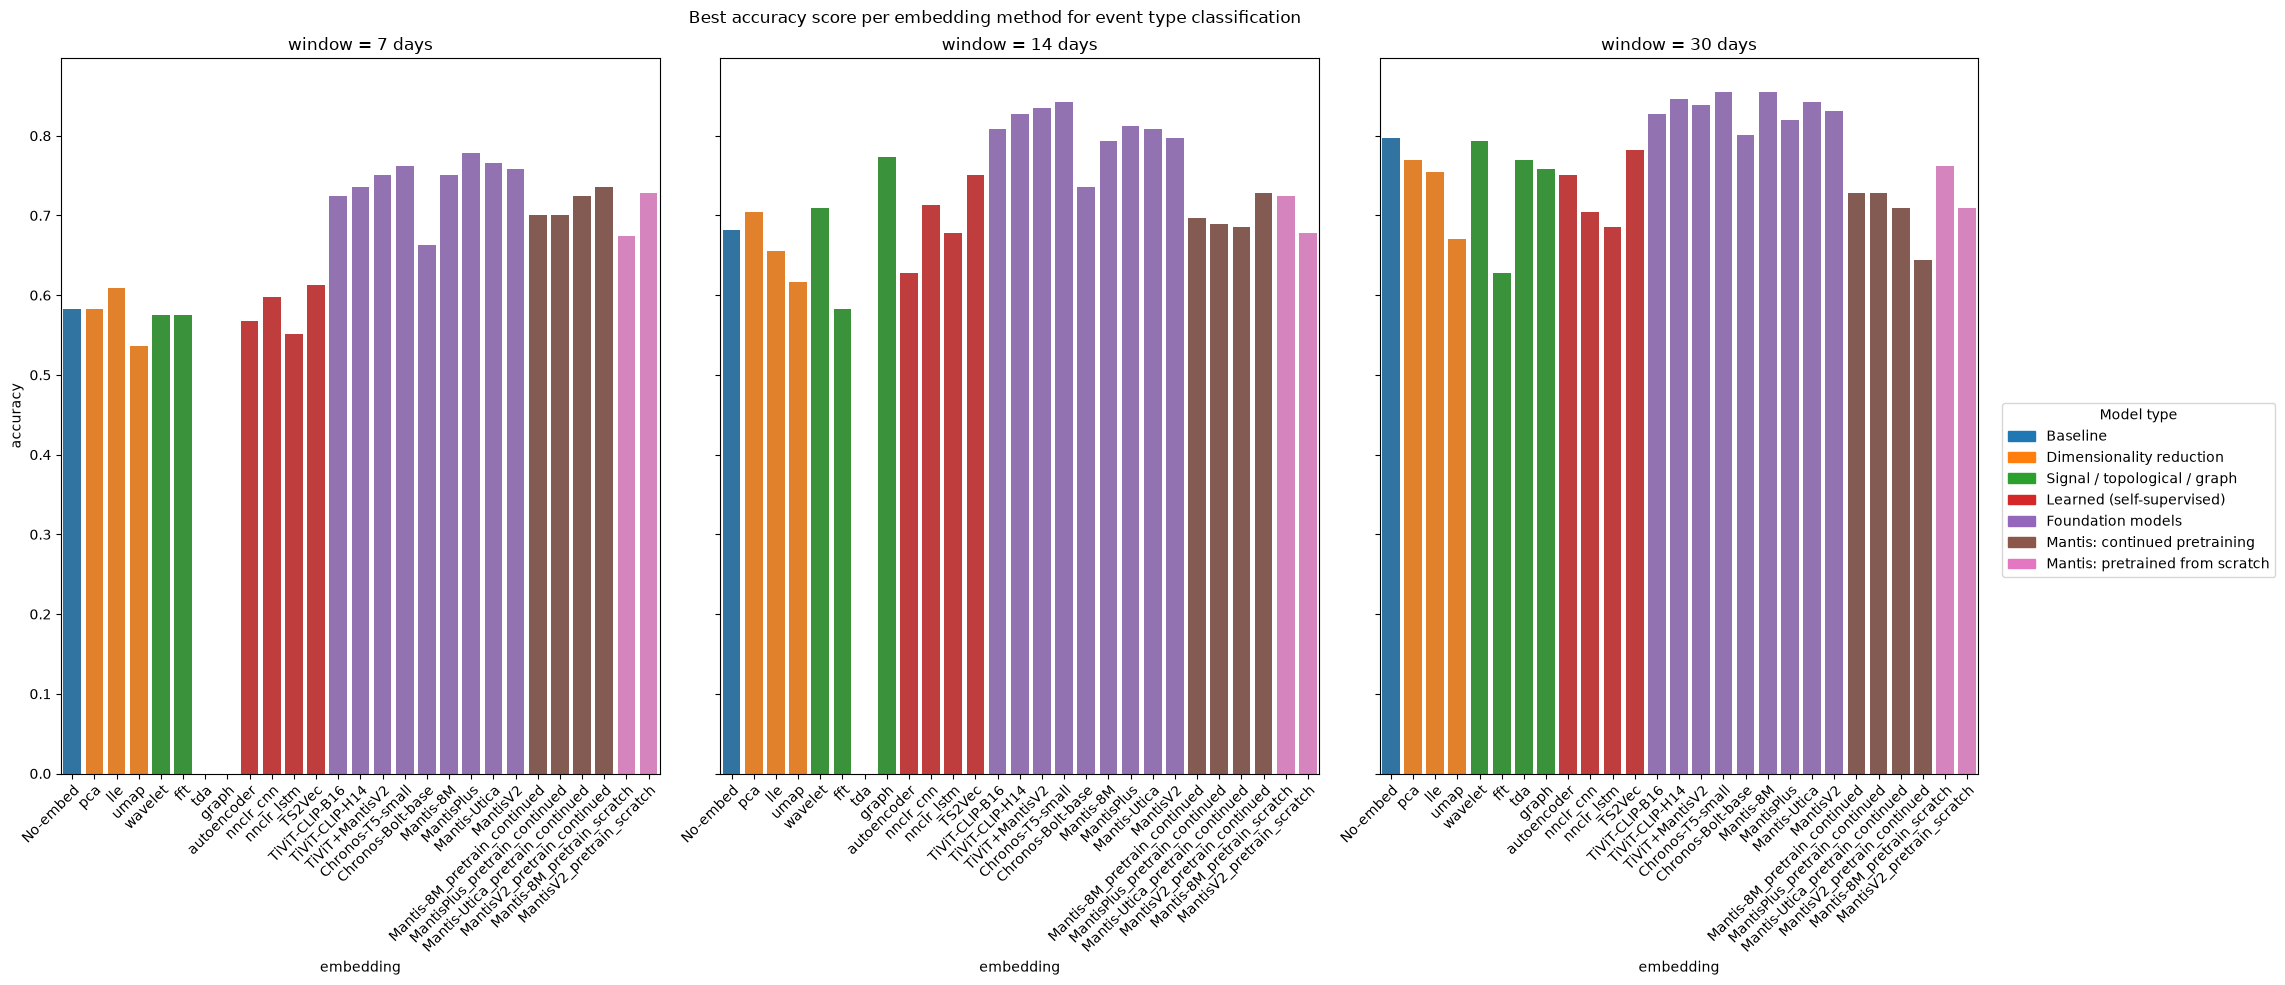

In [27]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# 1. Categories (adapt the grouping to your taste)
categories = {
    'Baseline': ['No-embed'],
    'Dimensionality reduction': ['pca', 'lle', 'umap'],
    'Signal / topological / graph': ['wavelet', 'fft', 'tda', 'graph'],
    'Learned (self-supervised)': ['autoencoder', 'nnclr_cnn', 'nnclr_lstm', 'TS2Vec'],
    'Foundation models': [
        'TiViT-CLIP-B16', 'TiViT-CLIP-H14', 'TiViT+MantisV2',
        'Chronos-T5-small', 'Chronos-Bolt-base',
        'Mantis-8M', 'MantisPlus', 'Mantis-Utica', 'MantisV2',
    ],
    'Mantis: continued pretraining': [
        'Mantis-8M_pretrain_continued', 'MantisPlus_pretrain_continued',
        'Mantis-Utica_pretrain_continued', 'MantisV2_pretrain_continued',
    ],
    'Mantis: pretrained from scratch': [
        'Mantis-8M_pretrain_scratch', 'MantisV2_pretrain_scratch',
    ],
}

# 2. One color per category
cat_colors = dict(zip(categories, sns.color_palette("tab10", len(categories))))

# 3. embedding -> color, and the x order (grouped by category)
emb_colors = {emb: cat_colors[cat] for cat, embs in categories.items() for emb in embs}
order = [emb for embs in categories.values() for emb in embs]
order = [e for e in order if e in df['embedding'].unique()]  # drop any missing ones

# 4. Plot
df_best = df[df['feature'] == 'event_type'].groupby(['embedding', 'window'])['accuracy'].max().reset_index()

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 10), sharey=True)

for i, window in enumerate(df['window'].unique()):
    sns.barplot(
        data=df_best[df_best['window'] == window],
        x="embedding",
        y="accuracy",
        order=order,
        hue="embedding",          # needed so the palette dict is applied per bar
        hue_order=order,
        palette=emb_colors,
        legend=False,
        ax=axes[i],
    )
    axes[i].tick_params("x", rotation=45)
    plt.setp(axes[i].get_xticklabels(), ha="right", rotation_mode="anchor")
    axes[i].set_title(f'window = {window} days')

# 5. One shared legend for the categories
handles = [mpatches.Patch(color=c, label=cat) for cat, c in cat_colors.items()]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), title="Model type")

fig.suptitle('Best accuracy score per embedding method for event type classification')
plt.tight_layout()
plt.show()

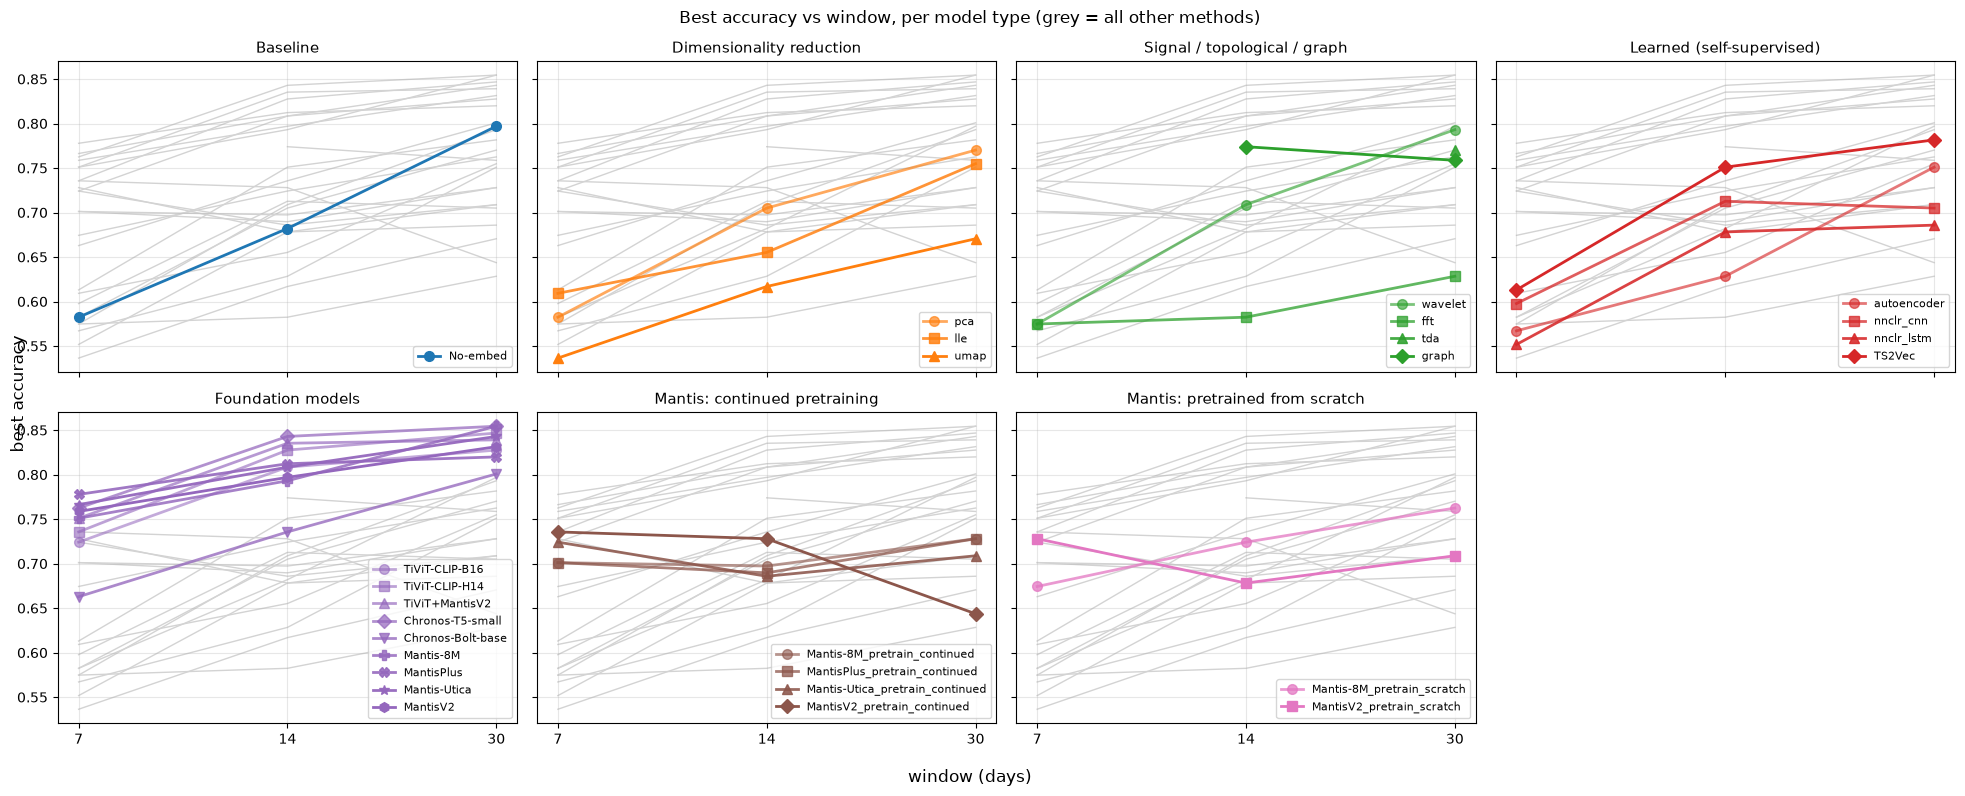

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# reuses `categories`, `cat_colors`, `emb_colors` from the earlier snippet
df_best = (df[df['feature'] == 'event_type']
           .groupby(['embedding', 'window'])['accuracy'].max().reset_index())
pivot = df_best.pivot(index='window', columns='embedding', values='accuracy')
windows = list(pivot.index)                      # [7, 14, 30]
x = np.arange(len(windows))                      # evenly spaced ticks (7 -> 14 -> 30 is not linear)

markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*', 'h']

ncols = 4
nrows = int(np.ceil(len(categories) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows),
                         sharex=True, sharey=True)
axes = axes.ravel()

for ax, (cat, embs) in zip(axes, categories.items()):
    # all other methods in light grey for context
    for emb in pivot.columns:
        if emb not in embs:
            ax.plot(x, pivot[emb], color='lightgrey', lw=1, zorder=1)

    # methods of this category in color
    for j, emb in enumerate([e for e in embs if e in pivot.columns]):
        ax.plot(x, pivot[emb], color=cat_colors[cat], lw=2,
                marker=markers[j % len(markers)], ms=7,
                alpha=0.5 + 0.5 * (j + 1) / len(embs),   # slight shade variation
                label=emb, zorder=3)

    ax.set_title(cat, fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(windows)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='lower right')

for ax in axes[len(categories):]:                # hide unused panels
    ax.set_visible(False)

fig.supxlabel('window (days)')
fig.supylabel('best accuracy')
fig.suptitle('Best accuracy vs window, per model type (grey = all other methods)')
plt.tight_layout()
plt.show()

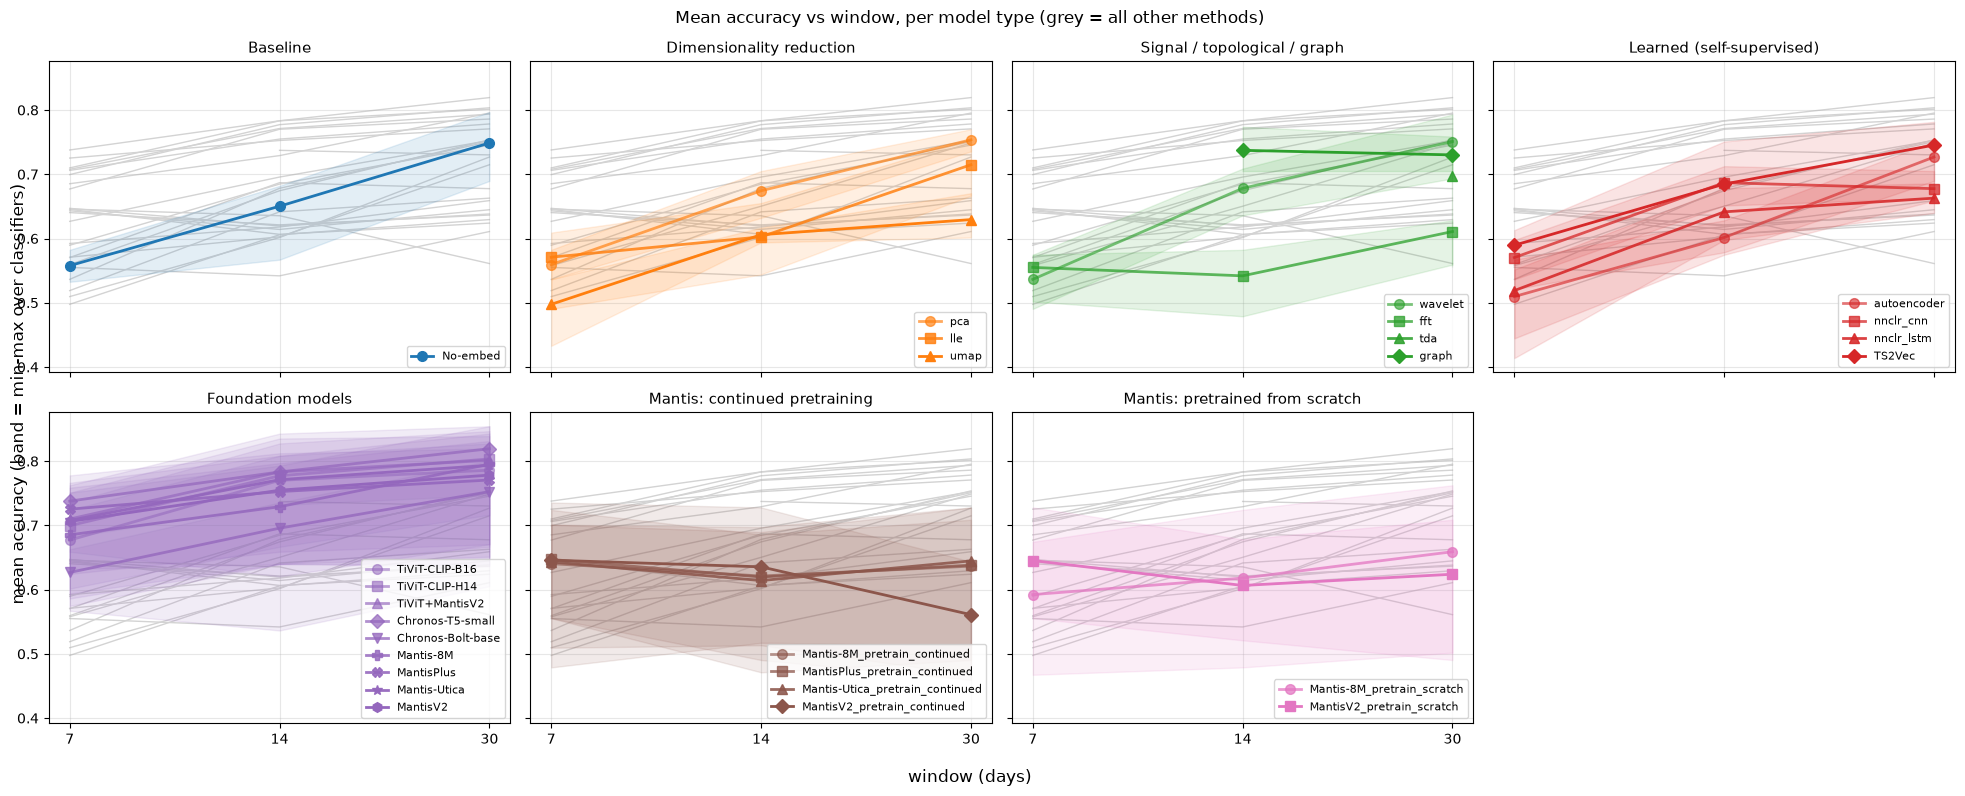

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# reuses `categories`, `cat_colors` from the earlier snippet
stats = (df[df['feature'] == 'event_type']
         .groupby(['embedding', 'window'])['accuracy']
         .agg(['mean', 'min', 'max'])
         .reset_index())

pivot_mean = stats.pivot(index='window', columns='embedding', values='mean')
pivot_min  = stats.pivot(index='window', columns='embedding', values='min')
pivot_max  = stats.pivot(index='window', columns='embedding', values='max')

windows = list(pivot_mean.index)          # [7, 14, 30]
x = np.arange(len(windows))
markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*', 'h']

ncols = 4
nrows = int(np.ceil(len(categories) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows),
                         sharex=True, sharey=True)
axes = axes.ravel()

SHOW_BAND = True   # min-max range across classifiers

for ax, (cat, embs) in zip(axes, categories.items()):
    # all other methods in light grey for context
    for emb in pivot_mean.columns:
        if emb not in embs:
            ax.plot(x, pivot_mean[emb], color='lightgrey', lw=1, zorder=1)

    for j, emb in enumerate([e for e in embs if e in pivot_mean.columns]):
        if SHOW_BAND:
            ax.fill_between(x, pivot_min[emb], pivot_max[emb],
                            color=cat_colors[cat], alpha=0.12, zorder=2)
        ax.plot(x, pivot_mean[emb], color=cat_colors[cat], lw=2,
                marker=markers[j % len(markers)], ms=7,
                alpha=0.5 + 0.5 * (j + 1) / len(embs),
                label=emb, zorder=3)

    ax.set_title(cat, fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(windows)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='lower right')

for ax in axes[len(categories):]:
    ax.set_visible(False)

fig.supxlabel('window (days)')
fig.supylabel('mean accuracy (band = min-max over classifiers)')
fig.suptitle('Mean accuracy vs window, per model type (grey = all other methods)')
plt.tight_layout()
plt.show()

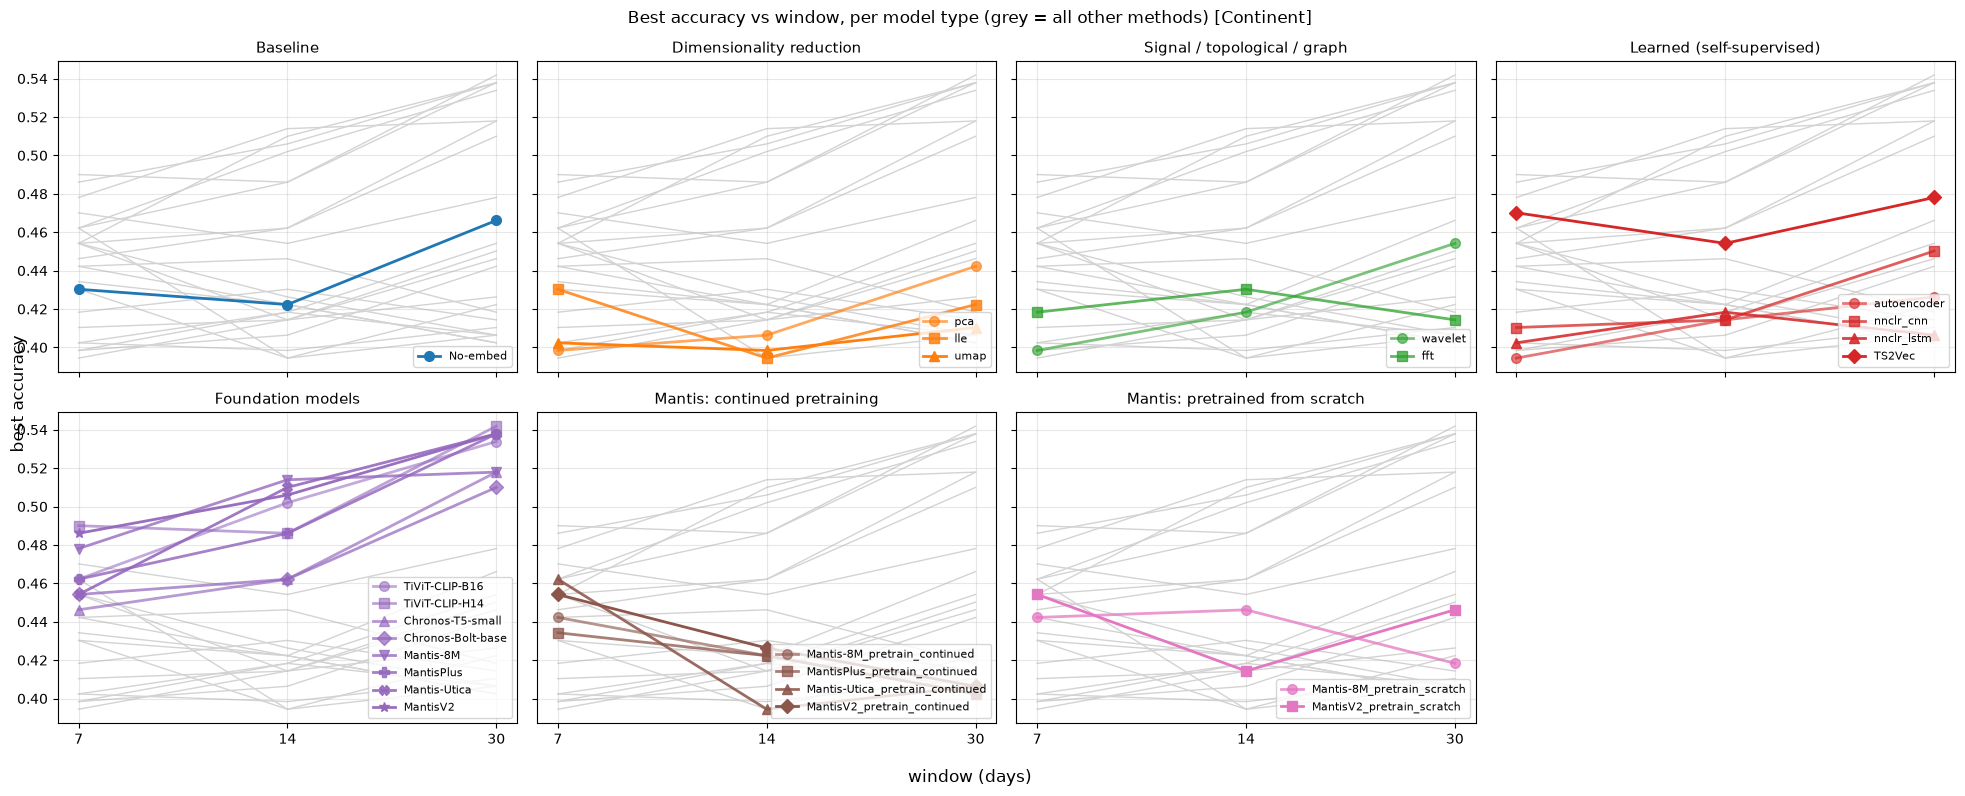

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# reuses `categories`, `cat_colors`, `emb_colors` from the earlier snippet
df_best = (df[df['feature'] == 'Continent']
           .groupby(['embedding', 'window'])['accuracy'].max().reset_index())
pivot = df_best.pivot(index='window', columns='embedding', values='accuracy')
windows = list(pivot.index)                      # [7, 14, 30]
x = np.arange(len(windows))                      # evenly spaced ticks (7 -> 14 -> 30 is not linear)

markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*', 'h']

ncols = 4
nrows = int(np.ceil(len(categories) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows),
                         sharex=True, sharey=True)
axes = axes.ravel()

for ax, (cat, embs) in zip(axes, categories.items()):
    # all other methods in light grey for context
    for emb in pivot.columns:
        if emb not in embs:
            ax.plot(x, pivot[emb], color='lightgrey', lw=1, zorder=1)

    # methods of this category in color
    for j, emb in enumerate([e for e in embs if e in pivot.columns]):
        ax.plot(x, pivot[emb], color=cat_colors[cat], lw=2,
                marker=markers[j % len(markers)], ms=7,
                alpha=0.5 + 0.5 * (j + 1) / len(embs),   # slight shade variation
                label=emb, zorder=3)

    ax.set_title(cat, fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(windows)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='lower right')

for ax in axes[len(categories):]:                # hide unused panels
    ax.set_visible(False)

fig.supxlabel('window (days)')
fig.supylabel('best accuracy')
fig.suptitle('Best accuracy vs window, per model type (grey = all other methods) [Continent]')
plt.tight_layout()
plt.show()

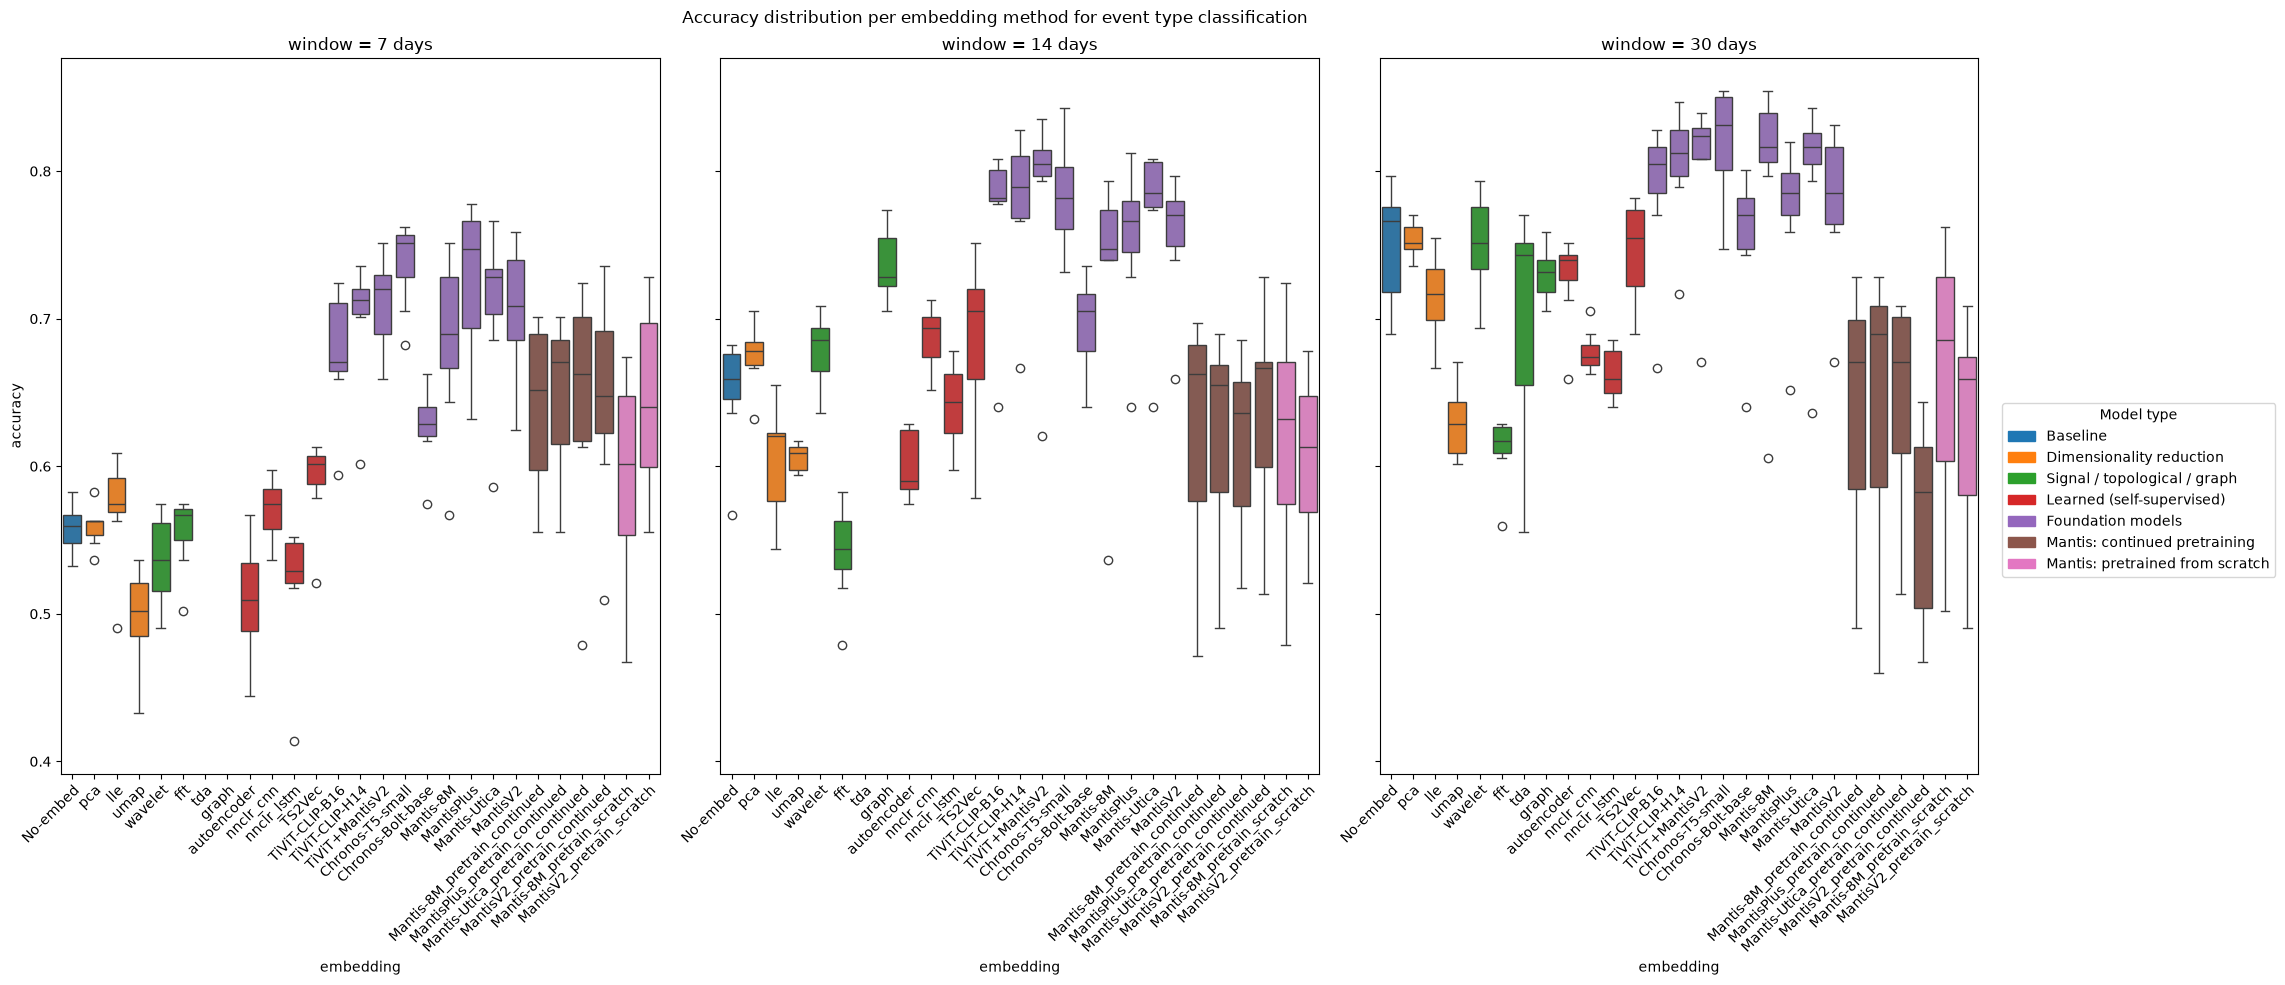

In [28]:
df_event = df[df['feature'] == 'event_type']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 10), sharey=True)

for i, window in enumerate(df['window'].unique()):
    sns.boxplot(
        data=df_event[df_event['window'] == window],
        x="embedding",
        y="accuracy",
        order=order,
        hue="embedding",
        hue_order=order,
        palette=emb_colors,
        legend=False,
        ax=axes[i],
    )
    axes[i].tick_params("x", rotation=45)
    plt.setp(axes[i].get_xticklabels(), ha="right", rotation_mode="anchor")
    axes[i].set_title(f'window = {window} days')

handles = [mpatches.Patch(color=c, label=cat) for cat, c in cat_colors.items()]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), title="Model type")

fig.suptitle('Accuracy distribution per embedding method for event type classification')
plt.tight_layout()
plt.show()

In [9]:
import pandas as pd

def read_classification_report(path):
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("precision"):
                continue
            parts = line.split()
            if parts[0] == "accuracy":
                # accuracy line has only: accuracy, f1, support
                rows.append({"label": "accuracy", "precision": None, "recall": None,
                             "f1-score": float(parts[1]), "support": int(parts[2])})
            else:
                # labels like "macro avg" / "weighted avg" contain a space
                label = " ".join(parts[:-4])
                p, r, f1, s = parts[-4:]
                rows.append({"label": label, "precision": float(p), "recall": float(r),
                             "f1-score": float(f1), "support": int(s)})
    return pd.DataFrame(rows)

path = "results_20261027_101142/event_type/data_7/data_7_wavelet_xgboost_classification_report.txt"
df_report = read_classification_report(path)
print(df_report)

          label  precision  recall  f1-score  support
0             0       0.45    0.43      0.44       74
1             1       0.50    0.50      0.50      109
2             2       0.52    0.54      0.53       78
3      accuracy        NaN     NaN      0.49      261
4     macro avg       0.49    0.49      0.49      261
5  weighted avg       0.49    0.49      0.49      261


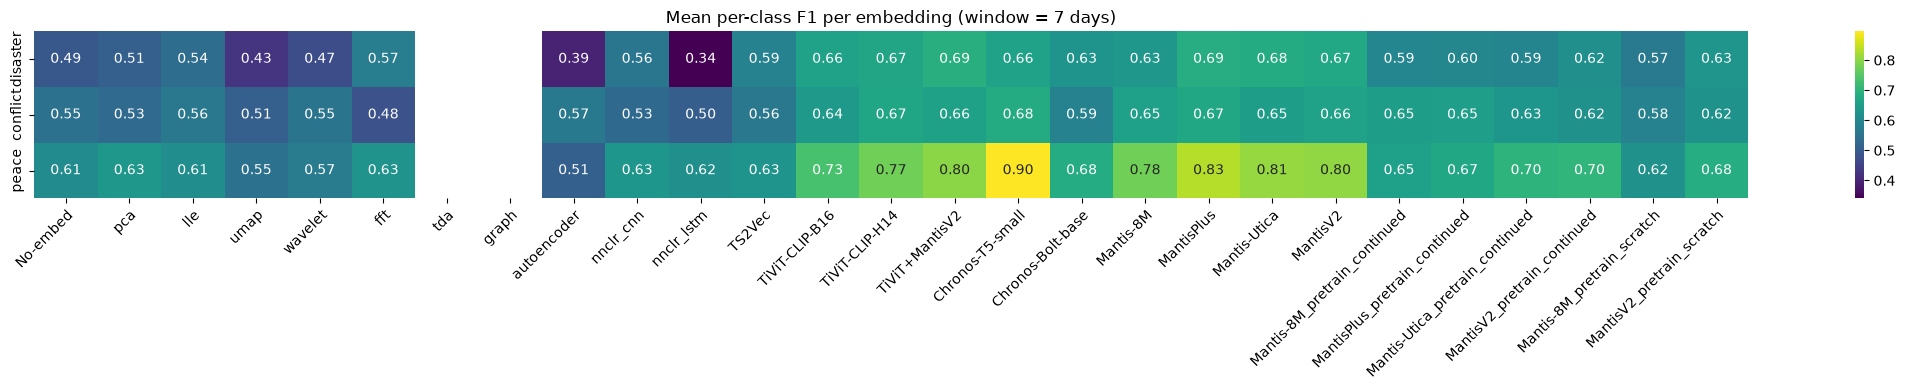

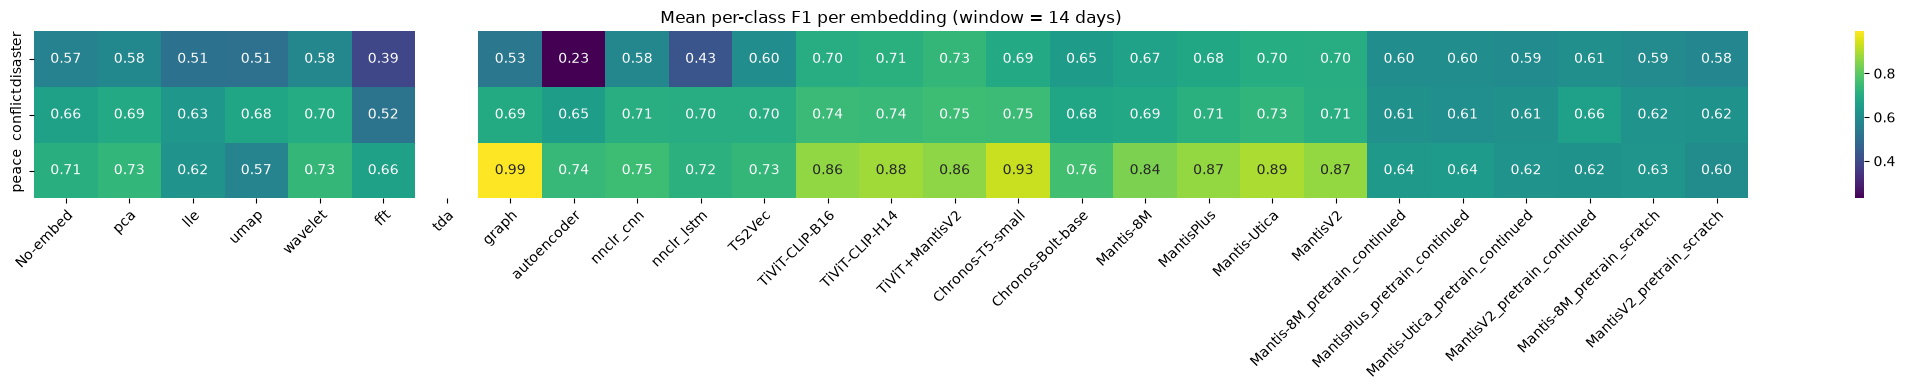

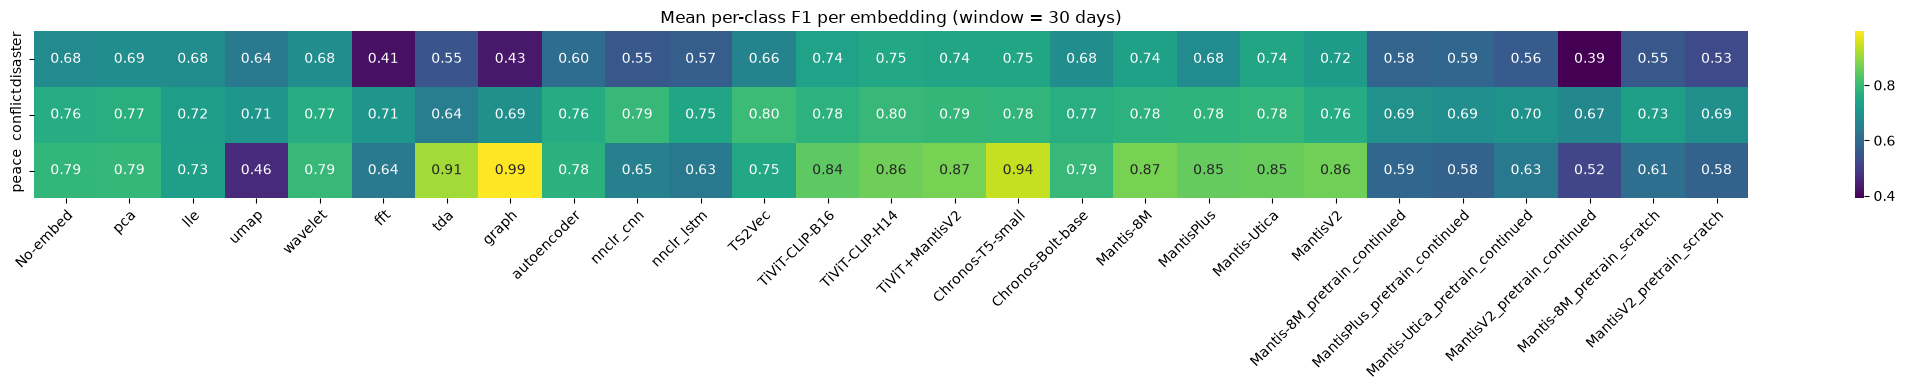

In [26]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

label_dict = {'disaster': 0, 'conflict': 1, 'peace': 2}
id2name = {str(v): k for k, v in label_dict.items()}
class_names = list(label_dict)

root = Path("results_20261027_101142")
windows = [7, 14, 30]

pattern = re.compile(
    r"data_(\d+)_(.+)_([^_]+)_classification_report(?:_\d{4}-\d{2}-\d{2}_\d{2}-\d{2}-\d{2})?$"
)

# ---------- load everything once ----------
records = []
for w in windows:
    for p in (root / "event_type" / f"data_{w}").glob("*_classification_report*.txt"):
        m = pattern.match(p.stem)
        if m is None:
            print("skipped:", p.name)
            continue
        window, embedding, model = m.groups()
        rep = read_classification_report(p)
        rep["label"] = rep["label"].replace(id2name)
        rep = rep.assign(feature="event_type", window=int(window),
                         embedding=embedding, model=model,
                         mtime=p.stat().st_mtime)
        records.append(rep)

df_full = pd.concat(records, ignore_index=True)

# keep only the most recent report per (window, embedding, model)
latest = df_full.groupby(["window", "embedding", "model"])["mtime"].transform("max")
df_full = df_full[df_full["mtime"] == latest]

d_cls = df_full[df_full.label.isin(class_names)]
x_order = [e for e in order if e in d_cls.embedding.unique()]

# ---------- one figure per window ----------
for w in windows:
    pivot = (
        d_cls[d_cls.window == w]
        .pivot_table(index="label", columns="embedding", values="f1-score", aggfunc="mean")
        .reindex(index=class_names, columns=x_order)
    )

    fig, ax = plt.subplots(figsize=(22, 4))
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="viridis", ax=ax)
    ax.set_title(f"Mean per-class F1 per embedding (window = {w} days)")
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.tight_layout()
    plt.show()

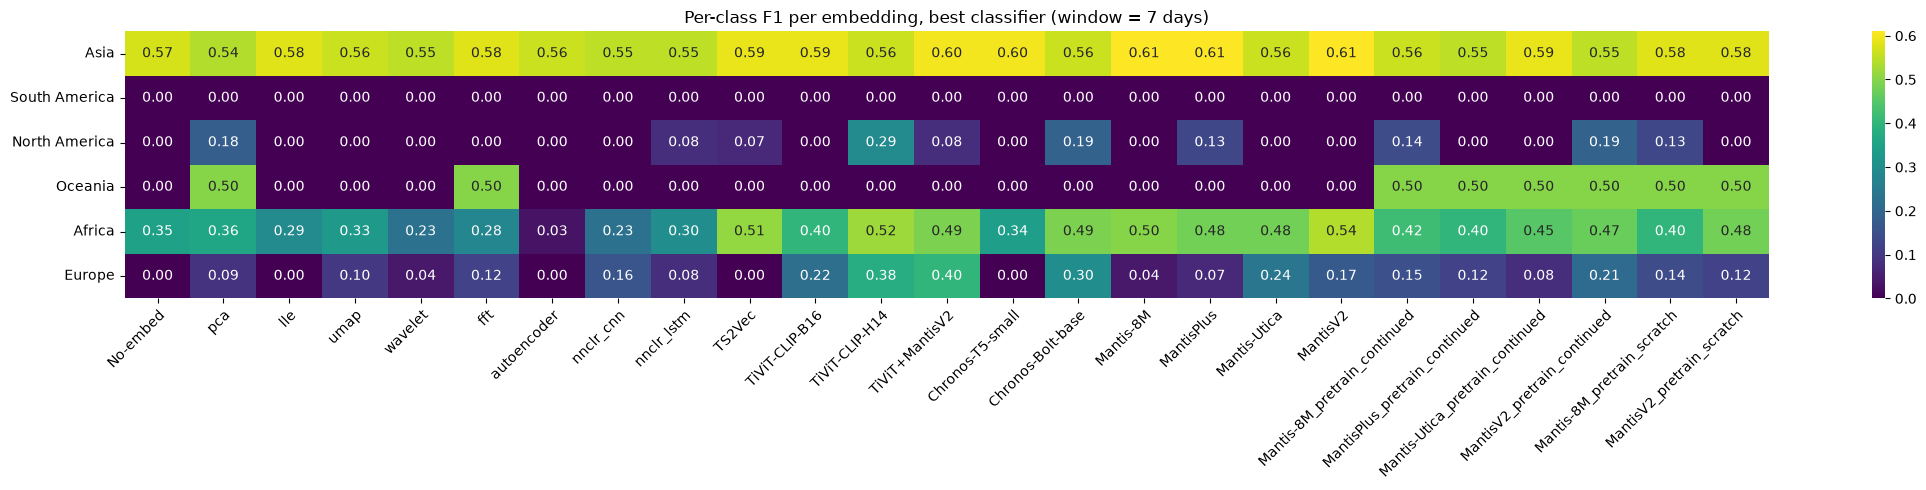

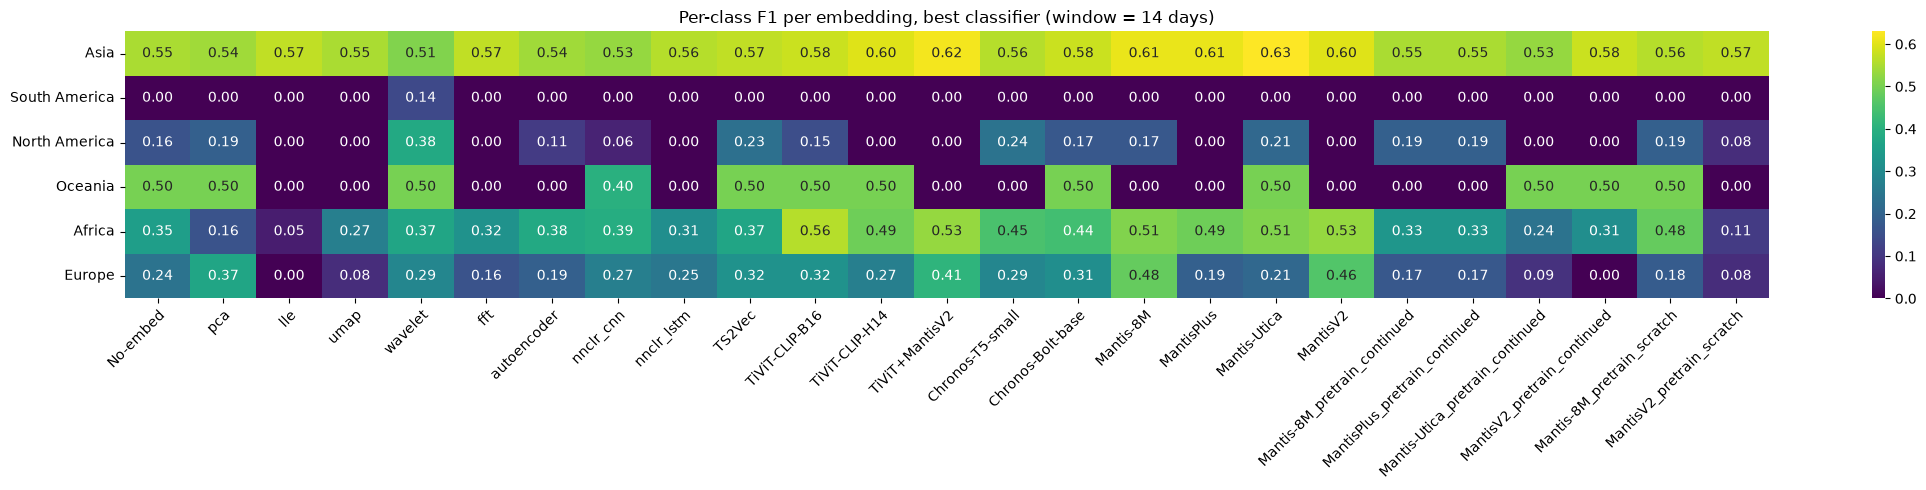

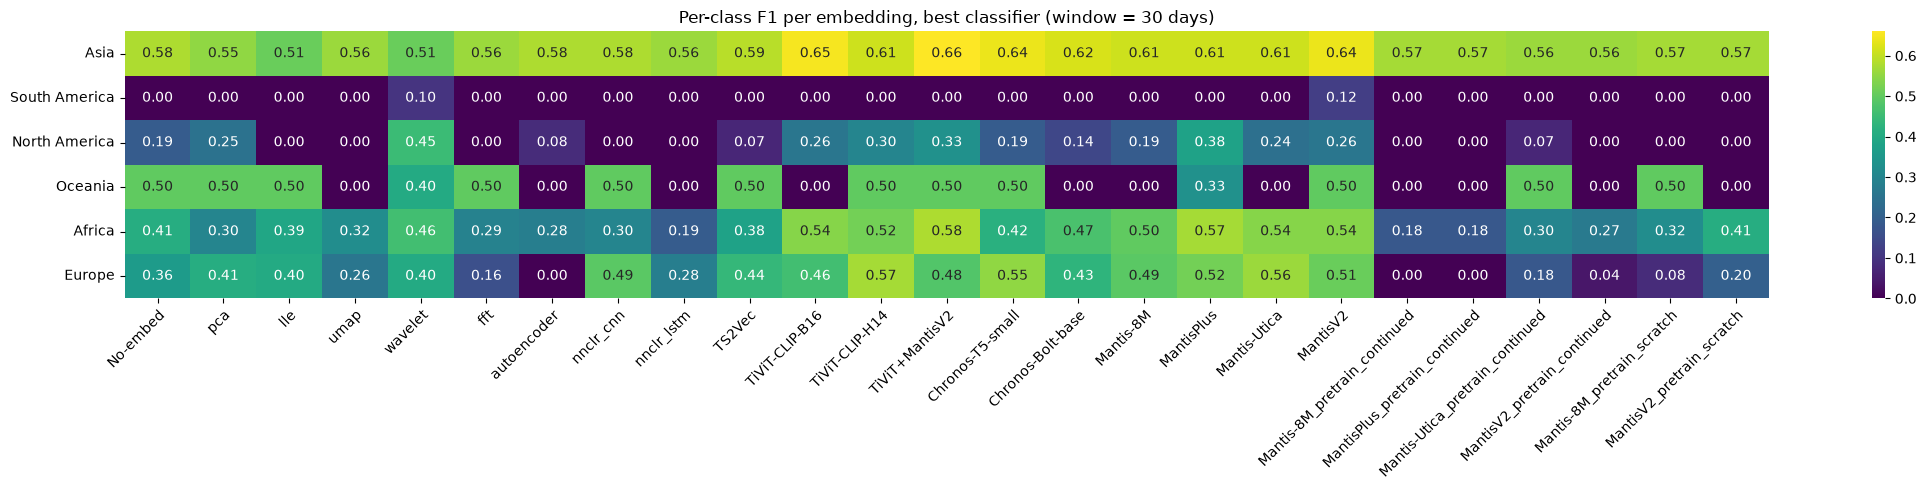

In [27]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

label_dict = {'Asia': 0, 'South America': 1, 'North America': 2,
              'Oceania': 3, 'Africa': 4, 'Europe': 5}
id2name = {str(v): k for k, v in label_dict.items()}
class_names = list(label_dict)

root_list = ['results_20261025_225531',
             'results_20261025_183402',
             'results_20261027_101142']
feature = "Continent"
windows = [7, 14, 30]
BEST_ONLY = True   # True: best classifier per embedding (by accuracy); False: mean over classifiers

pattern = re.compile(
    r"data_(\d+)_(.+)_([^_]+)_classification_report"
    r"(?:_\d{4}-\d{2}-\d{2}_\d{2}-\d{2}-\d{2})?$"
)

# ---------- load everything once ----------
records = []
for w in windows:
    for root in root_list:
        folder = Path(root) / feature / f"data_{w}"
        for p in folder.glob("*_classification_report*.txt"):
            m = pattern.match(p.stem)
            if m is None:
                print("skipped:", p)
                continue
            window, embedding, model = m.groups()
            rep = read_classification_report(p)
            rep["label"] = rep["label"].replace(id2name)
            rep = rep.assign(feature=feature, window=int(window), embedding=embedding,
                             model=model, root=root, mtime=p.stat().st_mtime)
            records.append(rep)

df_full = pd.concat(records, ignore_index=True)

# one report per (window, embedding, model): the most recent across roots/timestamps
run = ["window", "embedding", "model"]
df_full = df_full[df_full["mtime"] == df_full.groupby(run)["mtime"].transform("max")]

# optionally keep only the best classifier (by accuracy) per (window, embedding)
if BEST_ONLY:
    acc = df_full[df_full.label == "accuracy"][run + ["f1-score"]].rename(columns={"f1-score": "acc"})
    best = acc.loc[acc.groupby(["window", "embedding"])["acc"].idxmax(), run]
    df_full = df_full.merge(best, on=run)

d_cls = df_full[df_full.label.isin(class_names)]
x_order = [e for e in order if e in d_cls.embedding.unique()]

# ---------- one figure per window ----------
for w in windows:
    pivot = (
        d_cls[d_cls.window == w]
        .pivot_table(index="label", columns="embedding", values="f1-score", aggfunc="mean")
        .reindex(index=class_names, columns=x_order)
    )

    fig, ax = plt.subplots(figsize=(22, 5))
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="viridis", ax=ax)
    kind = "best classifier" if BEST_ONLY else "mean over classifiers"
    ax.set_title(f"Per-class F1 per embedding, {kind} (window = {w} days)")
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.tight_layout()
    plt.show()

# Heatmap of best 


In [16]:
df[df['feature'] == 'event_type'].sort_values(['accuracy'], ascending=False)

,feature,window,embedding,classifier,accuracy,time,params,error
549,event_type,30,Mantis-8M,svm,0.854406,1.010296,"{'C': 1, 'kernel': 'rbf', 'degree': 2, 'gamma'...",NaN
528,event_type,30,Chronos-T5-small,logreg,0.854406,63.164514,"{'C': 864.731825439002, 'fit_intercept': False...",NaN
532,event_type,30,Chronos-T5-small,xgboost,0.850575,42.301333,"{'n_estimators': 130, 'learning_rate': 0.40919...",NaN
530,event_type,30,Chronos-T5-small,rf,0.850575,30.184035,"{'n_estimators': 184, 'max_depth': 8}",NaN
544,event_type,30,Mantis-8M,logreg,0.850575,84.669290,"{'C': 0.02507585445663243, 'fit_intercept': Fa...",NaN
...,...,...,...,...,...,...,...,...
590,event_type,30,MantisPlus_pretrain_continued,mlp,NaN,NaN,NaN,OneHotEncoder.__init__() got an unexpected key...
598,event_type,30,Mantis-Utica_pretrain_continued,mlp,NaN,NaN,NaN,OneHotEncoder.__init__() got an unexpected key...
606,event_type,30,MantisV2_pretrain_continued,mlp,NaN,NaN,NaN,OneHotEncoder.__init__() got an unexpected key...
614,event_type,30,Mantis-8M_pretrain_scratch,mlp,NaN,NaN,NaN,OneHotEncoder.__init__() got an unexpected key...


In [24]:
def find_report(root, feature, window, embedding, classifier):
    folder = root / feature / f"data_{window}"
    stem = f"data_{window}_{embedding}_{classifier}_classification_report"
    matches = sorted(folder.glob(f"{stem}*.txt"))
    if not matches:
        raise FileNotFoundError(f"No report found for {stem}* in {folder}")
    return matches[-1]   # latest one if there are several

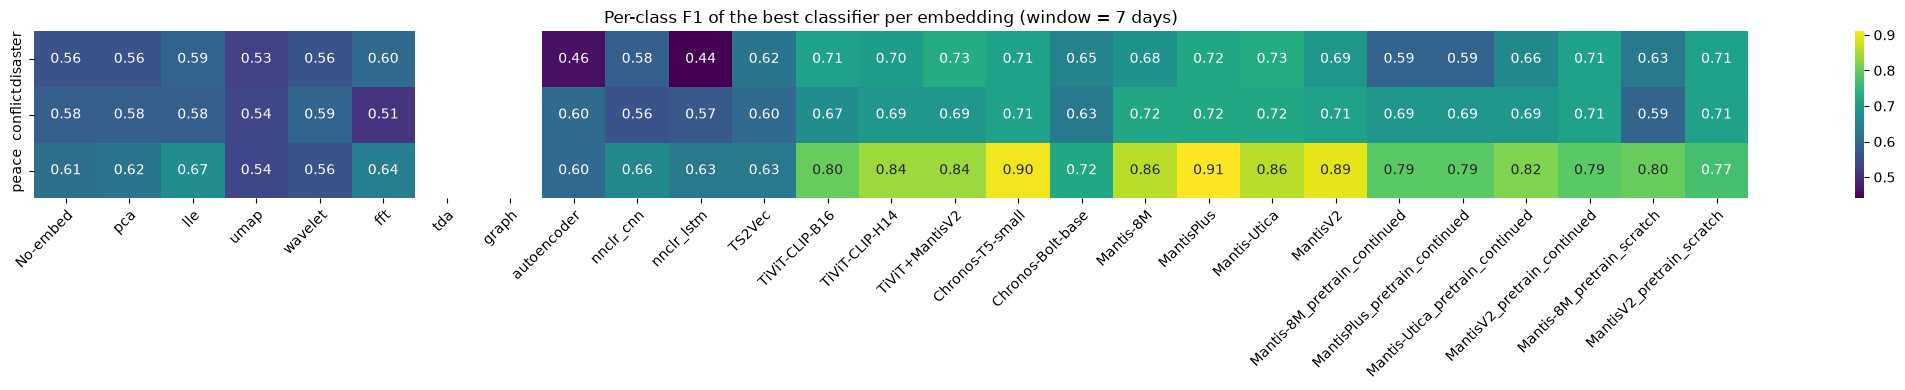

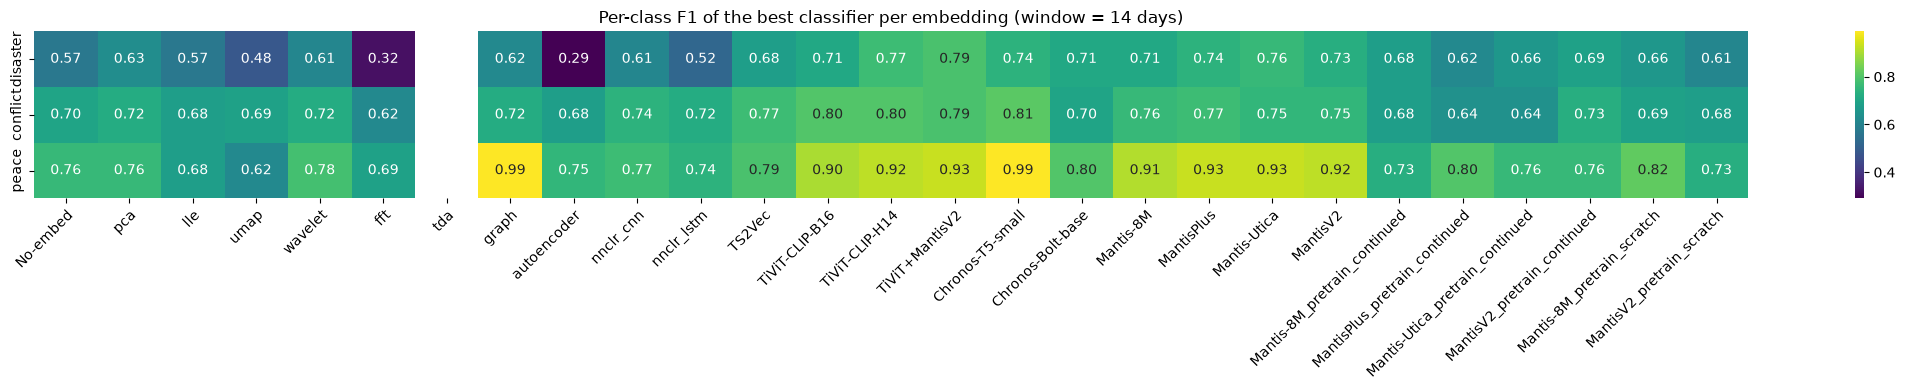

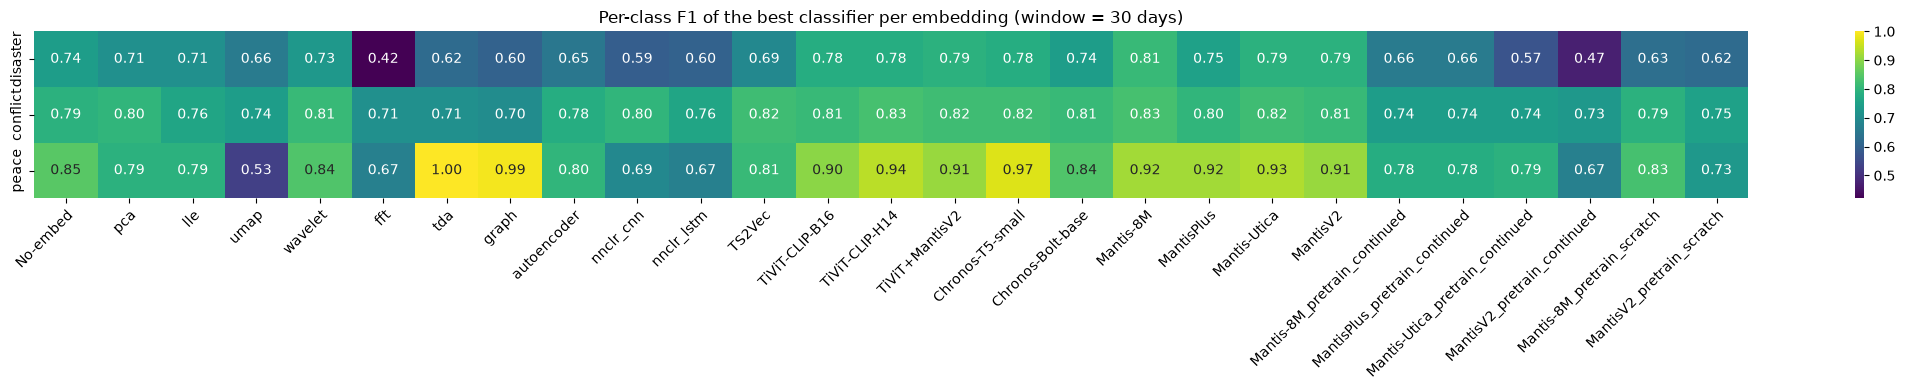

In [25]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path

label_dict = {'disaster': 0, 'conflict': 1, 'peace': 2}
id2name = {str(v): k for k, v in label_dict.items()}
class_names = list(label_dict)

root = Path("results_20261027_101142")
df_event = df[df['feature'] == 'event_type']
windows = [7, 14, 30]

# ---------- best classifier per (window, embedding) ----------
best = (
    df_event.loc[df_event.groupby(['window', 'embedding'])['accuracy'].idxmax()]
    [['window', 'embedding', 'classifier', 'accuracy']]
)

# ---------- load only those reports ----------
records = []
for row in best.itertuples(index=False):
    p = find_report(root, "event_type", row.window, row.embedding, row.classifier)
    rep = read_classification_report(p)
    rep["label"] = rep["label"].replace(id2name)
    rep = rep.assign(window=row.window, embedding=row.embedding, classifier=row.classifier)
    records.append(rep)

df_full = pd.concat(records, ignore_index=True)
d_cls = df_full[df_full.label.isin(class_names)]
x_order = [e for e in order if e in d_cls.embedding.unique()]

# ---------- one figure per window ----------
for w in windows:
    pivot = (
        d_cls[d_cls.window == w]
        .pivot(index="label", columns="embedding", values="f1-score")
        .reindex(index=class_names, columns=x_order)
    )

    fig, ax = plt.subplots(figsize=(22, 4))
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="viridis", ax=ax)
    ax.set_title(f"Per-class F1 of the best classifier per embedding (window = {w} days)")
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.tight_layout()
    plt.show()

In [35]:
pivot.columns

Index(['dt', 'knn', 'logreg', 'mlp', 'nb', 'rf', 'svm', 'xgboost'], dtype='object', name='classifier')

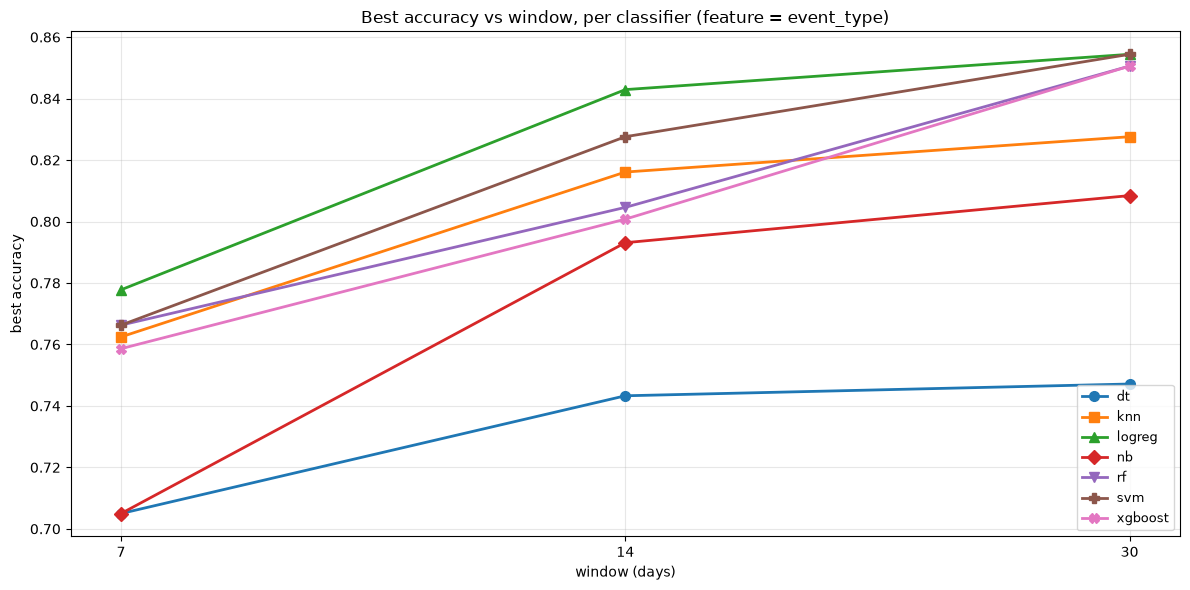

In [38]:
import matplotlib.pyplot as plt
import numpy as np

df_best = (df[df['feature'] == 'event_type']
           .groupby(['classifier', 'window'])['accuracy'].max().reset_index())
pivot = df_best.pivot(index='window', columns='classifier', values='accuracy').dropna(axis=1)
windows = list(pivot.index)                      # [7, 14, 30]
x = np.arange(len(windows))

markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*', 'h']

plt.figure(figsize=(12, 6))

for j, clf in enumerate(pivot.columns):
    plt.plot(x, pivot[clf], marker=markers[j % len(markers)], ms=7, lw=2, label=clf)

plt.xticks(ticks=x, labels=windows)
plt.grid(alpha=0.3)
plt.legend(fontsize=9, loc='lower right')
plt.xlabel('window (days)')
plt.ylabel('best accuracy')
plt.title('Best accuracy vs window, per classifier (feature = event_type)')
plt.tight_layout()
plt.show()

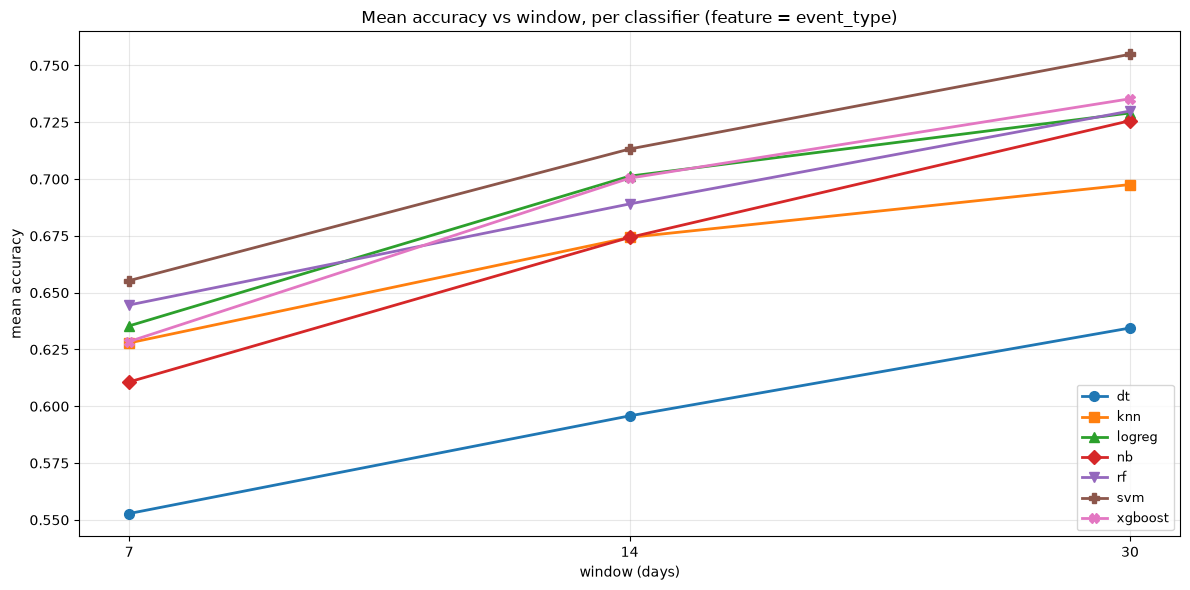

In [39]:
import matplotlib.pyplot as plt
import numpy as np

df_best = (df[df['feature'] == 'event_type']
           .groupby(['classifier', 'window'])['accuracy'].mean().reset_index())
pivot = df_best.pivot(index='window', columns='classifier', values='accuracy').dropna(axis=1)
windows = list(pivot.index)                      # [7, 14, 30]
x = np.arange(len(windows))

markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*', 'h']

plt.figure(figsize=(12, 6))

for j, clf in enumerate(pivot.columns):
    plt.plot(x, pivot[clf], marker=markers[j % len(markers)], ms=7, lw=2, label=clf)

plt.xticks(ticks=x, labels=windows)
plt.grid(alpha=0.3)
plt.legend(fontsize=9, loc='lower right')
plt.xlabel('window (days)')
plt.ylabel('mean accuracy')
plt.title('Mean accuracy vs window, per classifier (feature = event_type)')
plt.tight_layout()
plt.show()

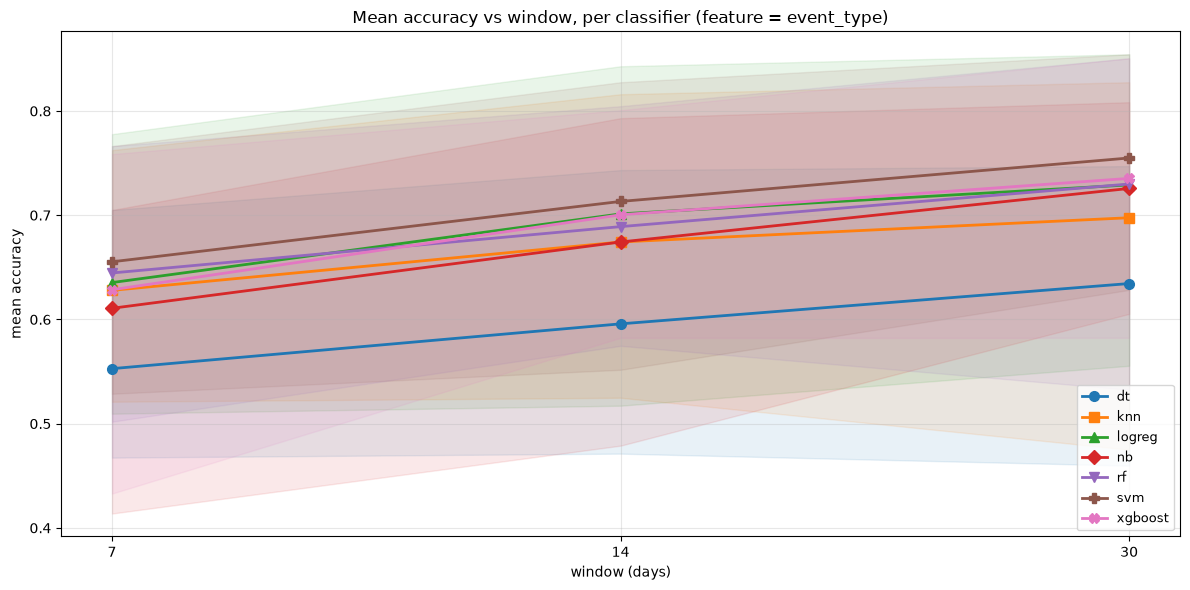

In [40]:
import matplotlib.pyplot as plt
import numpy as np

stats = (df[df['feature'] == 'event_type']
         .groupby(['classifier', 'window'])['accuracy']
         .agg(['mean', 'min', 'max'])
         .reset_index())

pivot_mean = stats.pivot(index='window', columns='classifier', values='mean').dropna(axis=1)
pivot_min  = stats.pivot(index='window', columns='classifier', values='min')[pivot_mean.columns]
pivot_max  = stats.pivot(index='window', columns='classifier', values='max')[pivot_mean.columns]

windows = list(pivot_mean.index)                 # [7, 14, 30]
x = np.arange(len(windows))
markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*', 'h']
colors = plt.cm.tab10.colors

SHOW_BAND = True   # min-max range across embeddings

plt.figure(figsize=(12, 6))

for j, clf in enumerate(pivot_mean.columns):
    c = colors[j % len(colors)]
    if SHOW_BAND:
        plt.fill_between(x, pivot_min[clf], pivot_max[clf], color=c, alpha=0.10)
    plt.plot(x, pivot_mean[clf], color=c, marker=markers[j % len(markers)],
             ms=7, lw=2, label=clf)

plt.xticks(ticks=x, labels=windows)
plt.grid(alpha=0.3)
plt.legend(fontsize=9, loc='lower right')
plt.xlabel('window (days)')
plt.ylabel('mean accuracy')
plt.title('Mean accuracy vs window, per classifier (feature = event_type)')
plt.tight_layout()
plt.show()

In [60]:
df_event

,feature,window,embedding,classifier,accuracy,time,params,error
0,event_type,7,No-embed,logreg,0.555556,2.530921,"{'C': 0.04156171663895603, 'fit_intercept': Tr...",NaN
1,event_type,7,No-embed,dt,0.540230,0.511361,"{'max_depth': 29, 'criterion': 'gini'}",NaN
2,event_type,7,No-embed,rf,0.570881,7.324304,"{'n_estimators': 144, 'max_depth': 15}",NaN
3,event_type,7,No-embed,knn,0.582375,0.487049,"{'n_neighbors': 9, 'weights': 'distance', 'alg...",NaN
4,event_type,7,No-embed,xgboost,0.559387,9.339139,"{'n_estimators': 118, 'learning_rate': 0.10755...",NaN
...,...,...,...,...,...,...,...,...
619,event_type,30,MantisV2_pretrain_scratch,knn,0.490421,1.288358,"{'n_neighbors': 17, 'weights': 'uniform', 'alg...",NaN
620,event_type,30,MantisV2_pretrain_scratch,xgboost,0.681992,47.907762,"{'n_estimators': 146, 'learning_rate': 0.03367...",NaN
621,event_type,30,MantisV2_pretrain_scratch,svm,0.708812,1.213651,"{'C': 1, 'kernel': 'rbf', 'degree': 3, 'gamma'...",NaN
622,event_type,30,MantisV2_pretrain_scratch,mlp,NaN,NaN,NaN,OneHotEncoder.__init__() got an unexpected key...


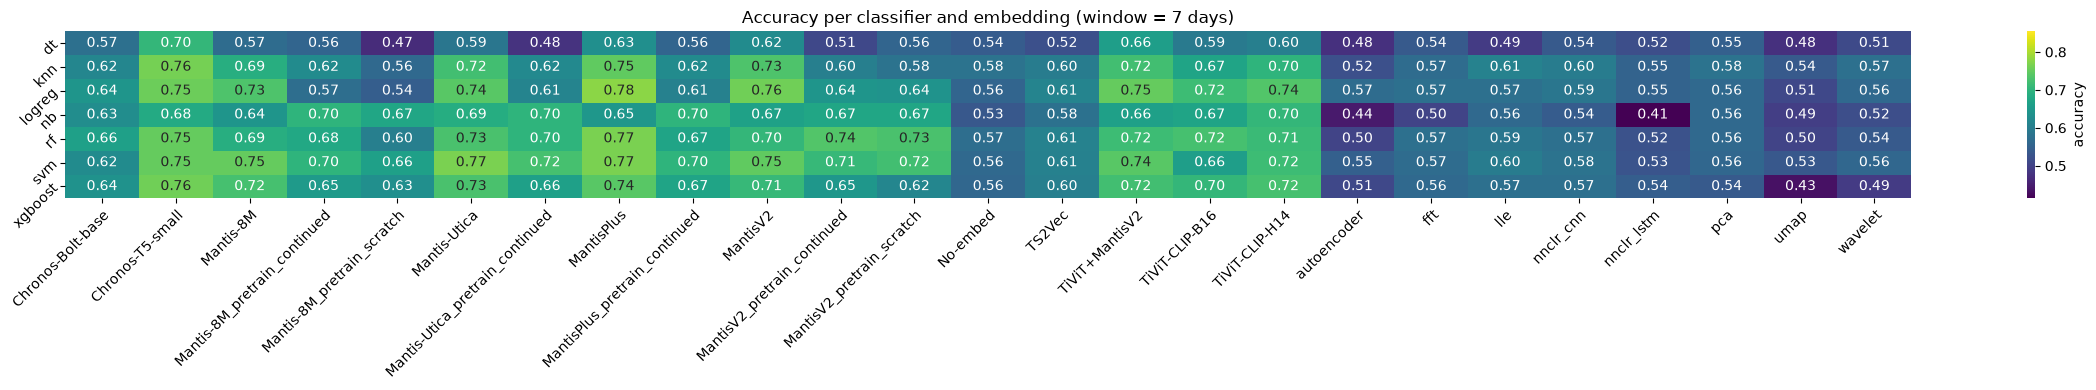

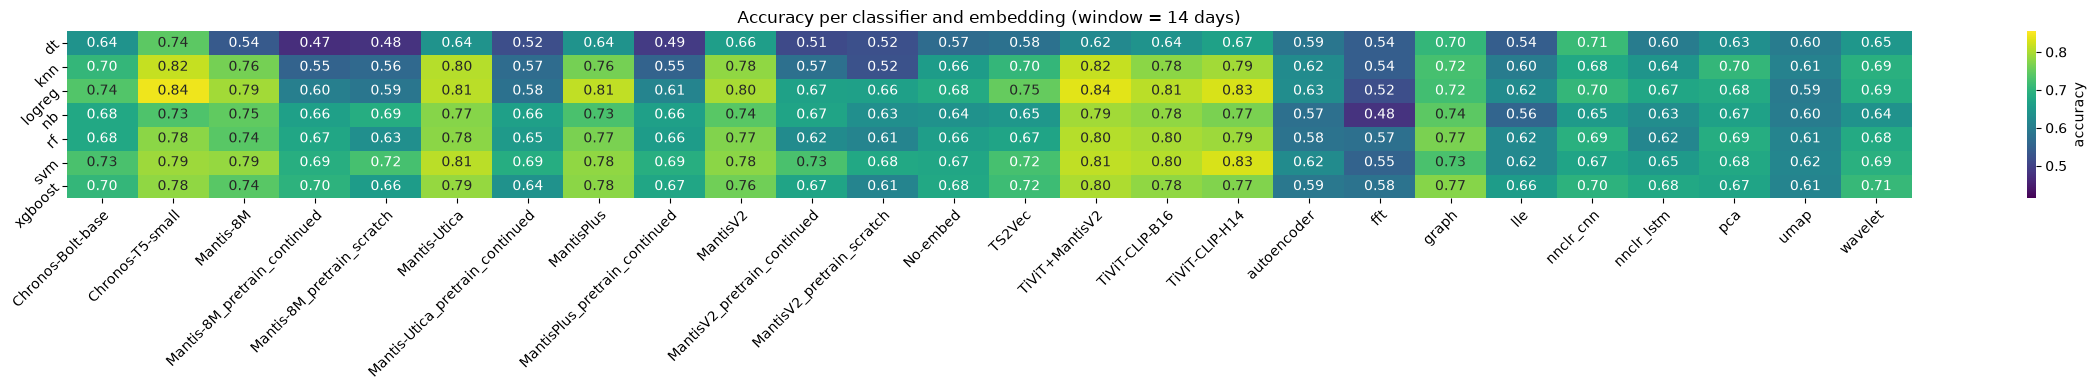

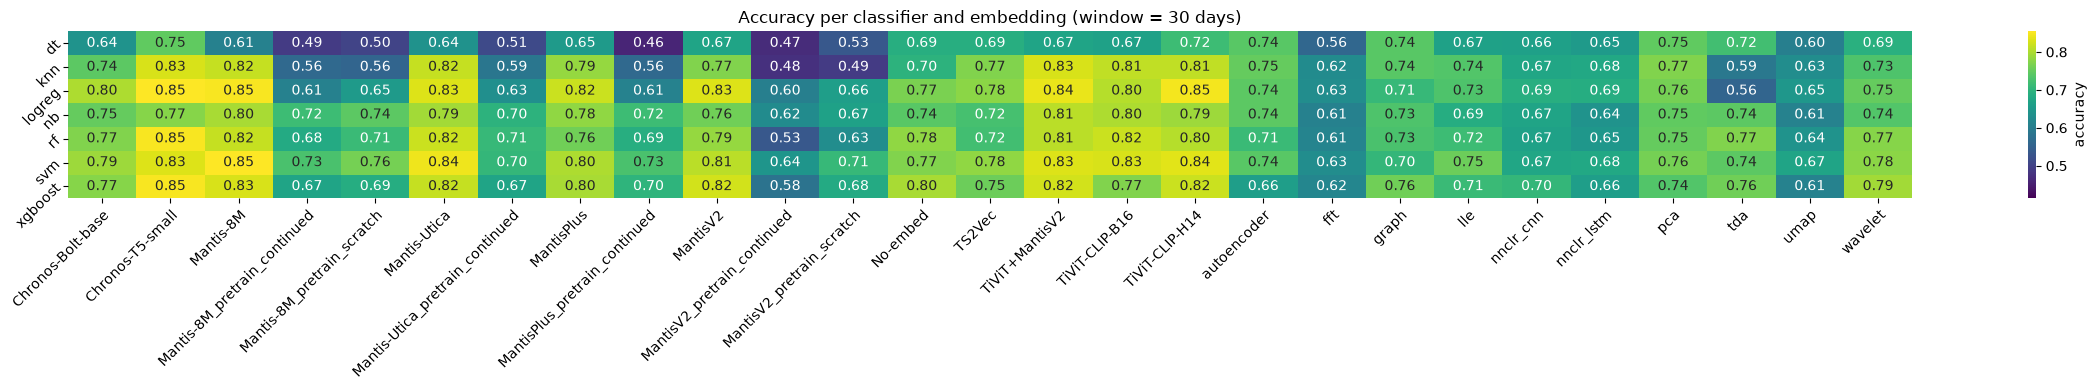

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns
df_event = df[df['feature'] == 'event_type']
min_acc = df_event['accuracy'].min()
max_acc = df_event['accuracy'].max()
# reuses `order` from the earlier snippet (embeddings grouped by category)
for w in [7, 14, 30]:
    pivot = (
        df_event[df_event['window'] == w]
        .pivot_table(index='classifier', columns='embedding', values='accuracy')
        #.reindex(columns=[e for e in order if e in df_event['embedding'].unique()])
    ).dropna()

    fig, ax = plt.subplots(figsize=(24, 4))
    sns.heatmap(pivot, cmap="viridis", annot=True, fmt=".2f", ax=ax,
                cbar_kws={"label": "accuracy"}, vmin=min_acc, vmax= max_acc)
    ax.set_title(f"Accuracy per classifier and embedding (window = {w} days)")
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.setp(ax.get_yticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.tight_layout()
    plt.show()

In [64]:
df100 = pd.read_csv('mantis_14d_continued_100_epoch_results.csv')

df20 = df[(df['feature'] == 'event_type') & (df['window'] == 14) & (df['embedding'] == 'Mantis-8M_pretrain_continued')]

In [67]:
df100['embedding'] = 'epoch 100'
df20['embedding'] = 'epoch 20'
pd.concat([df100, df20])

/tmp/ipykernel_3382701/3851272203.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df20['embedding'] = 'epoch 20'


,feature,window,embedding,classifier,accuracy,time,params,error
0,event_type,14,epoch 100,logreg,0.716475,115.481664,"{'C': 0.013346544746121885, 'fit_intercept': T...",NaN
1,event_type,14,epoch 100,logreg,0.716475,115.481664,"{'C': 0.013346544746121885, 'fit_intercept': T...",NaN
2,event_type,14,epoch 100,dt,0.521073,4.358084,"{'max_depth': 32, 'criterion': 'entropy'}",NaN
3,event_type,14,epoch 100,logreg,0.716475,115.481664,"{'C': 0.013346544746121885, 'fit_intercept': T...",NaN
4,event_type,14,epoch 100,dt,0.521073,4.358084,"{'max_depth': 32, 'criterion': 'entropy'}",NaN
5,event_type,14,epoch 100,rf,0.681992,29.564021,"{'n_estimators': 137, 'max_depth': 21}",NaN
6,event_type,14,epoch 100,logreg,0.716475,115.481664,"{'C': 0.013346544746121885, 'fit_intercept': T...",NaN
7,event_type,14,epoch 100,dt,0.521073,4.358084,"{'max_depth': 32, 'criterion': 'entropy'}",NaN
8,event_type,14,epoch 100,rf,0.681992,29.564021,"{'n_estimators': 137, 'max_depth': 21}",NaN
9,event_type,14,epoch 100,knn,0.735632,1.361156,"{'n_neighbors': 20, 'weights': 'distance', 'al...",NaN


<Axes: xlabel='embedding', ylabel='classifier'>

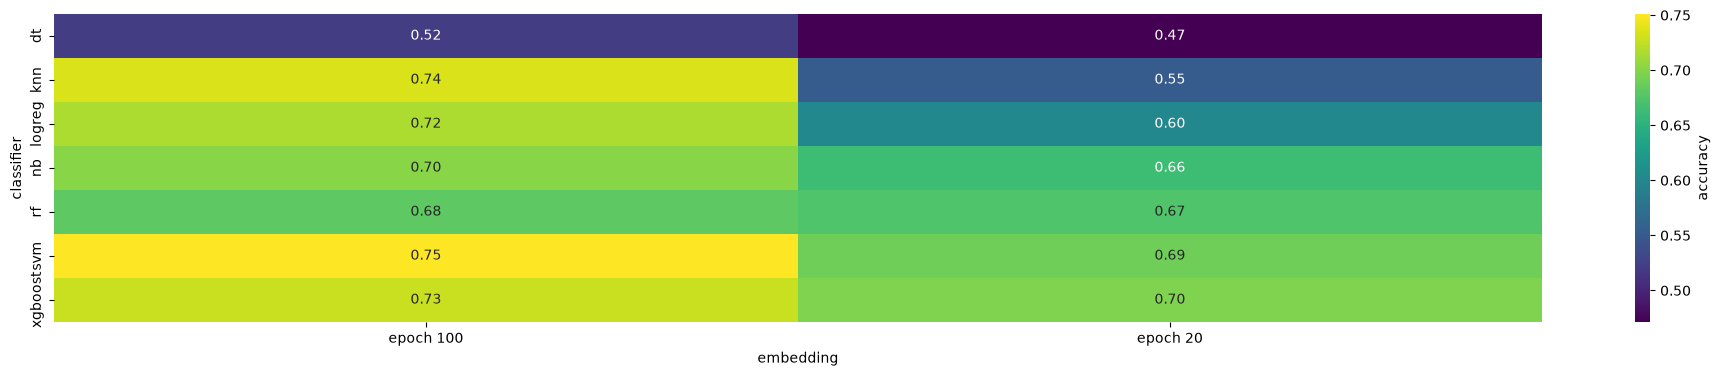

In [68]:
pivot = (
        pd.concat([df100, df20])
        .pivot_table(index='classifier', columns='embedding', values='accuracy')
        #.reindex(columns=[e for e in order if e in df_event['embedding'].unique()])
    ).dropna()

fig, ax = plt.subplots(figsize=(24, 4))
sns.heatmap(pivot, cmap="viridis", annot=True, fmt=".2f", ax=ax,
                cbar_kws={"label": "accuracy"})